# Introduction to Machine Learning -- MC886
# Assignment 2 - Model Selection and Regularization

**Professor:** Marcelo da Silva Reis  
**PED:** Heigon Soldera

In [1]:
# Please, enter your name and RA number in the lines below:
print("Lucas Gomes Bussinger da Silva", "|", "247314")
print("Caíque Andrade", "|", "204677")
print("Jorge Felipe Lopes Pereira", "|", "251771")

Lucas Gomes Bussinger da Silva | 247314
Caíque Andrade | 204677
Jorge Felipe Lopes Pereira | 251771


---

## Objective

This assignment investigates the effects of overfitting in different data regimes
and test conditions.
The goal is to understand the different results of regularization when data
availability changes, and how they impact the generalization across **three**
different distributions: the one used for training, the clean one, and a
corruption the model has never seen.

### Guidelines

> Please read these guidelines carefully.

1. Questions can be answered in English or in Portuguese.

2. Use data visualization as a primary tool for understanding the problem. Inspect the training data, corrupted inputs, and model behavior. When an assumption is uncertain, verify it empirically through plots.

3. The provided code serves only as a reference. Modifications are allowed, including changes to functions and the introduction of new components. Code clarity and organization are required.

4. The use of generative AI tools (e.g., ChatGPT, GitHub Copilot, DeepSeek, LLaMA) is permitted strictly for implementation support. The use of AI for interpreting, analyzing, or discussing experimental results is discouraged. Submissions must include:
   - A declaration of which models were used.
   - The prompts that generated any incorporated code.

5. Do not hesitate to reach out to the PED/PAD via Discord.

### About the Dataset

This assignment uses the [MNIST](https://web.archive.org/web/20240213122836/http://yann.lecun.com/exdb/mnist/) dataset, a standard benchmark for image classification. It consists of 28×28 grayscale images of handwritten digits (0–9), where each pixel encodes an intensity value in [0, 255].

MNIST is useful here because it is simple enough that a linear model can do well on it, which means the learned weights are directly interpretable as images, where each weight corresponds to the influence of each pixel.

To study robustness and distribution shift, the images were corrupted with one of the corruptions of [MNIST-C](https://github.com/google-research/mnist-c) (Mu & Gilmer, 2019). Which corruption it is, is for you to find out in Part 1.

The training set consists entirely of corrupted images. The test set contains **three splits** of the same 10,000 test images:
- `test_corrupted`: corrupted test images (same corruption as training).
- `test_clean`: the original, uncorrupted MNIST test images.
- `test_impulse`: the test images with a **different** corruption, impulse (salt-and-pepper) noise, never seen during training.

Performance on `test_corrupted` measures how well the model learned the training task.
Performance on `test_clean` measures how well the model learned digit recognition.
Performance on `test_impulse` measures whether the robustness acquired during training transfers to a corruption the model was never exposed to.

Your job is to train three different models, each one with different number of
available samples:
- Full-data (60000 samples)
- Partial-data (10000 samples)
- Scarce-data (1000 samples)

Finding the best combination of hyper-parameter for each one of them.

In [2]:
from typing import Any
import os
import time

from numpy.typing import NDArray
import numpy as np
import pandas as pd
import random

import torch
import torch.nn as nn
from torch import optim
from sklearn.model_selection import StratifiedKFold

import matplotlib.pyplot as plt
import seaborn as sns

# Set random seeds for reproducibility.
# Do not tune this number
# Re-run the notebook from the beginning before submitting.
seed = 42
torch.random.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

# O treino full-batch é limitado pela banda de memória (X_full ocupa ~190 MB em float32):
# poucos threads já saturam a banda e evitam overhead de sincronização.
torch.set_num_threads(min(6, os.cpu_count() or 1))

In [3]:
# The dataset is available in the classroom assignment.
# Ensure you have downloaded it and placed it alongside this notebook.

# DO NOT change this cell

def subsample_dataset(
    X: NDArray[Any], y: NDArray[Any], n: int
) -> tuple[NDArray[Any], NDArray[Any]]:
    n_samples = len(y)

    idxs = np.random.choice(
        n_samples, size=n, replace=False
    )

    return X[idxs], y[idxs]

DATA_DIR = "data_2s2026"

X_full = np.load(f"{DATA_DIR}/train/train_images.npy")
y_full = np.load(f"{DATA_DIR}/train/train_labels.npy")

X_partial, y_partial = subsample_dataset(X_full, y_full, 10_000)
X_scarce, y_scarce = subsample_dataset(X_full, y_full, 1_000)

print(f"Full-data set: {X_full.shape[0]} samples")
print(f"Partial-data set: {X_partial.shape[0]} samples")
print(f"Scarce-data set: {X_scarce.shape[0]} samples")

Full-data set: 60000 samples
Partial-data set: 10000 samples
Scarce-data set: 1000 samples


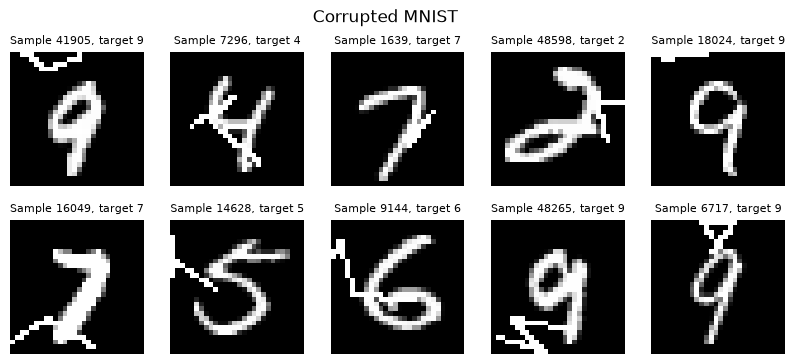

In [4]:
n_cols = 5
n_rows = 2

fig, axs = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(2*n_cols, 2*n_rows))

fig.suptitle("Corrupted MNIST")

for i in range(n_rows):
    for j in range(n_cols):
        ax = axs[i, j]
        idx = random.randint(0, len(X_full)-1)

        ax.set_title(f"Sample {idx}, target {y_full[idx]}", fontsize=8)
        ax.imshow(X_full[idx], cmap='grey')
        ax.set_axis_off()

---

## Part 1. Data Analysis and Preprocessing

### 1.1 Exploring the corruption

**(1.0 point)**

Before any modeling, understand what the corruption actually does to the data.

Is the corruption random per-pixel noise, or is it a structured perturbation?
Explore the **training** dataset, understand the distribution and the effects of the introduced
noise. Useful tools are per-class mean images, per-pixel statistics (e.g., how often each
pixel is saturated at 255), and looking at many individual samples side by side.

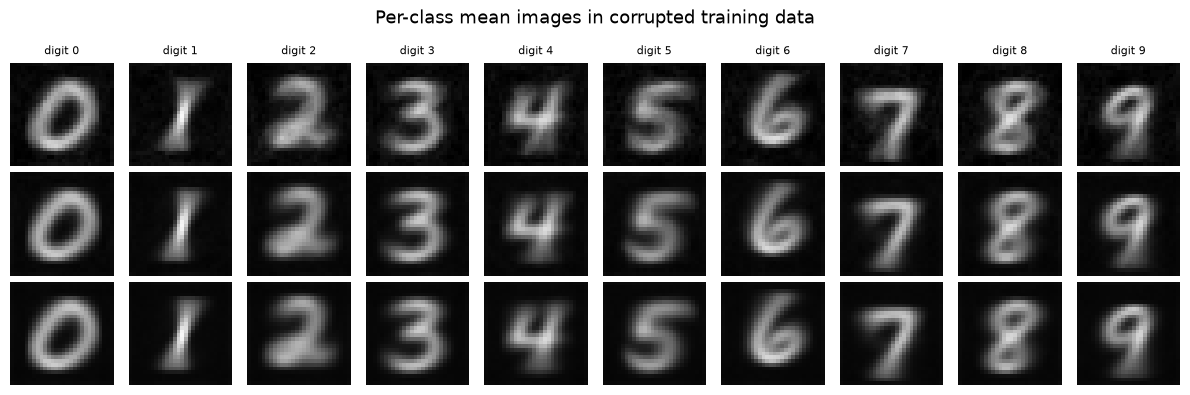

In [5]:
data_regimes = {
    "Scarce": (X_scarce, y_scarce),
    "Partial": (X_partial, y_partial),
    "Full": (X_full, y_full),
}

fig, axs = plt.subplots(len(data_regimes), 10, figsize=(4*len(data_regimes), 4))
for digit in range(10):
    axs[0, digit].set_title(f"digit {digit}", fontsize=8)

for i, name in enumerate(data_regimes):
    X, y = data_regimes[name]


    for digit in range(10):
        mask = (y == digit)
        mean_img = X[mask].mean(axis=0)
        axs[i, digit].imshow(mean_img, cmap="gray", vmin=0, vmax=255)
        axs[i, digit].axis("off")

    axs[i, 0].set_ylabel(f"{name}-data regime", fontsize=9)

plt.suptitle("Per-class mean images in corrupted training data", fontsize=13)
plt.tight_layout()
plt.show()

#### Visualizações adicionais da corrupção

Todas as análises abaixo usam **apenas o conjunto de treino** (Full-data), já que os conjuntos de teste
só podem ser consultados na Parte 4. O canal único das imagens é descartado para facilitar a indexação.

shape bruto: (60000, 28, 28, 1) | dtype: uint8 | faixa: 0 - 255


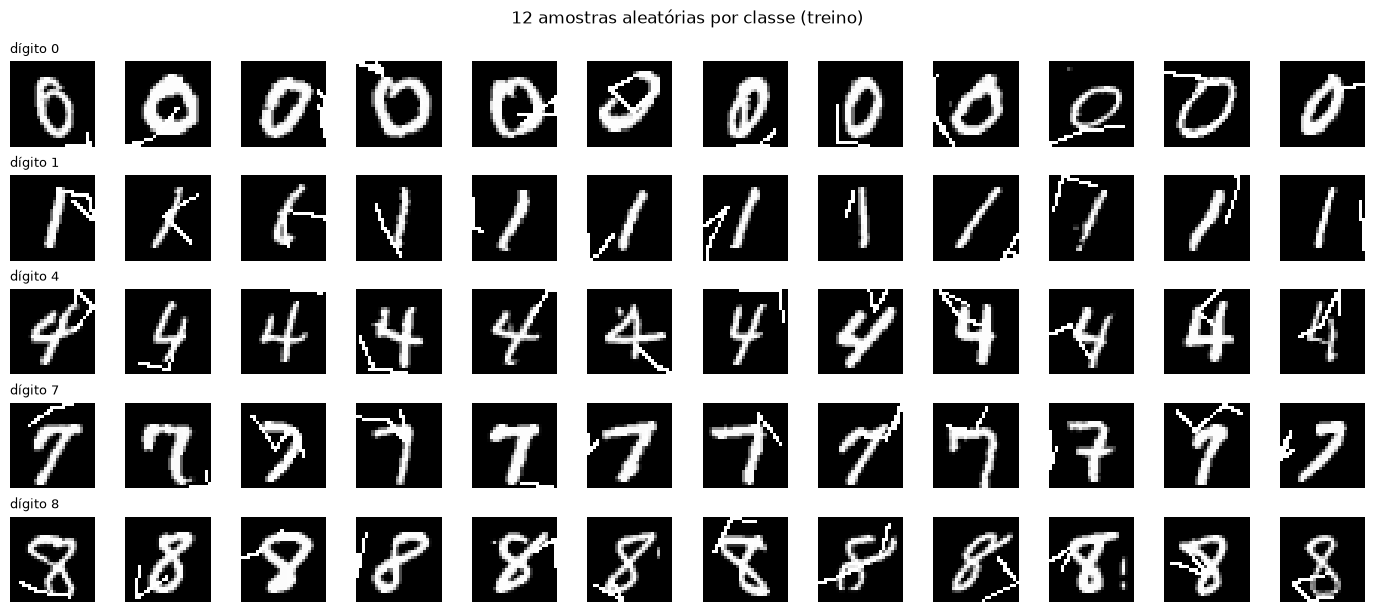

In [6]:
imgs_full = X_full[..., 0]  # (60000, 28, 28)
print("shape bruto:", X_full.shape, "| dtype:", X_full.dtype, "| faixa:", X_full.min(), "-", X_full.max())

# (1) Muitas amostras da mesma classe lado a lado: se a corrupção fosse um padrão fixo
# compartilhado, ela apareceria no mesmo lugar em todas as imagens.
rng_vis = np.random.default_rng(seed)
digits_to_show = [0, 1, 4, 7, 8]
fig, axs = plt.subplots(len(digits_to_show), 12, figsize=(14, 6.2))
for row, digit in enumerate(digits_to_show):
    idxs = rng_vis.choice(np.flatnonzero(y_full == digit), size=12, replace=False)
    for col, idx in enumerate(idxs):
        axs[row, col].imshow(imgs_full[idx], cmap="gray", vmin=0, vmax=255)
        axs[row, col].axis("off")
    axs[row, 0].set_title(f"dígito {digit}", fontsize=9, loc="left")
fig.suptitle("12 amostras aleatórias por classe (treino)")
plt.tight_layout()
plt.show()

Os traços extras são linhas finas e retas, quase sempre formando uma ou duas "quebras" (zigue-zague),
em posições, orientações e comprimentos diferentes em cada imagem. Para isolar a corrupção do dígito sem
olhar o conjunto limpo, usamos duas propriedades verificáveis no próprio treino:

1. **Intensidade.** Os traços do MNIST original são suavizados (anti-aliasing), então têm bordas com
   valores intermediários; um traço desenhado sinteticamente pode ser binário.
2. **Posição.** O MNIST centraliza os dígitos (caixa de 20×20 centrada pelo centro de massa), então a
   moldura externa de 1 pixel quase nunca contém tinta do dígito. O que aparece ali é corrupção.

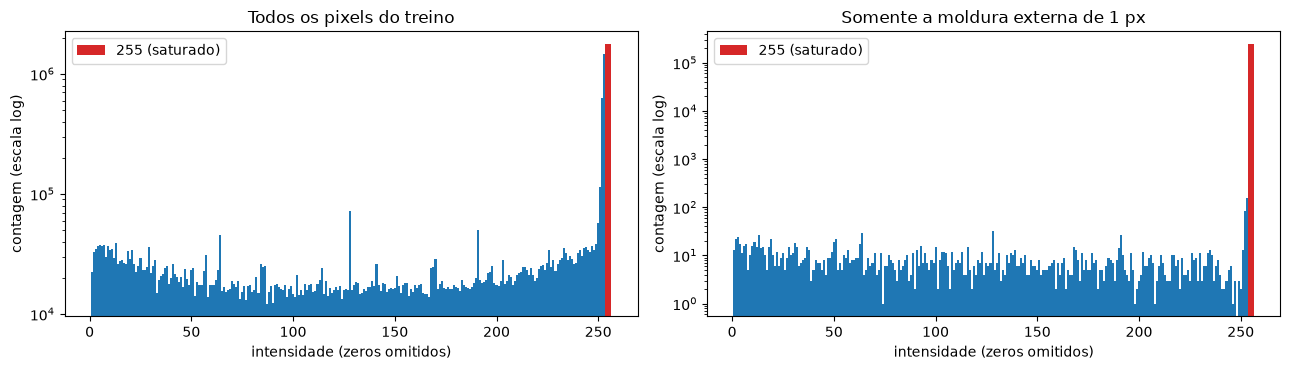

Moldura: 3.77% dos pixels são não nulos; destes, 99.06% valem exatamente 255.
Imagem inteira: 17.35% dos pixels não nulos valem 255 (contagem de 254 = 775,240; de 255 = 1,763,350).


In [7]:
frame_mask = np.zeros((28, 28), dtype=bool)
frame_mask[[0, -1], :] = True
frame_mask[:, [0, -1]] = True  # moldura externa de 1 px (108 pixels)

all_vals = imgs_full.ravel()
frame_vals = imgs_full[:, frame_mask].ravel()

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, vals, title in [(axs[0], all_vals, "Todos os pixels do treino"),
                        (axs[1], frame_vals, "Somente a moldura externa de 1 px")]:
    counts = np.bincount(vals, minlength=256)
    ax.bar(np.arange(1, 256), counts[1:], width=1.0, color="tab:blue")
    ax.bar([255], counts[255], width=3.0, color="tab:red", label="255 (saturado)")
    ax.set_yscale("log")
    ax.set_xlabel("intensidade (zeros omitidos)")
    ax.set_ylabel("contagem (escala log)")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

nz_frame = frame_vals[frame_vals > 0]
nz_all = all_vals[all_vals > 0]
print(f"Moldura: {np.mean(frame_vals > 0):.2%} dos pixels são não nulos; destes, {np.mean(nz_frame == 255):.2%} valem exatamente 255.")
print(f"Imagem inteira: {np.mean(nz_all == 255):.2%} dos pixels não nulos valem 255 "
      f"(contagem de 254 = {np.sum(all_vals == 254):,}; de 255 = {np.sum(all_vals == 255):,}).")

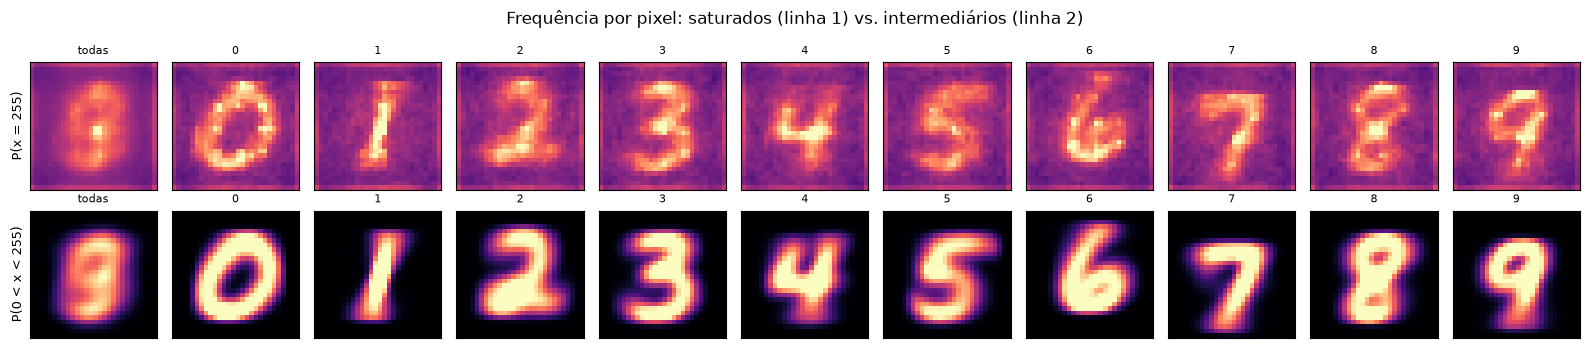

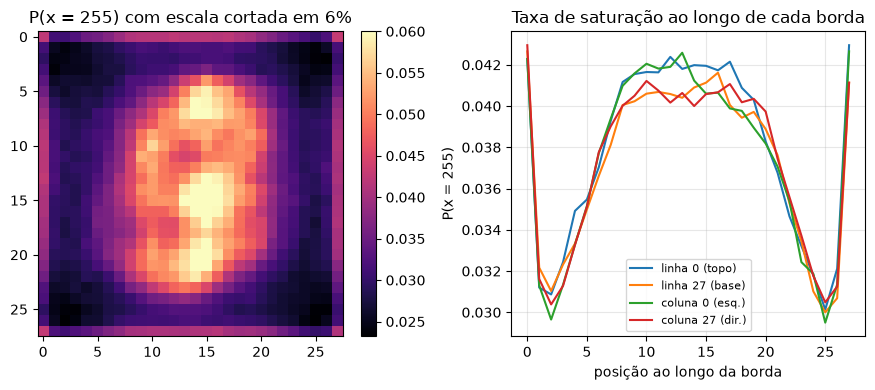

In [8]:
# (3) Frequência, por pixel, de cada tipo de valor.
#  - P(x = 255): soma do miolo dos traços do dígito com TODA a corrupção (binária).
#  - P(0 < x < 255): só aparece nas bordas suavizadas do dígito -> mapa "sem corrupção".
sat = (imgs_full == 255)
mid = (imgs_full > 0) & (imgs_full < 255)

fig, axs = plt.subplots(2, 11, figsize=(16, 3.6))
for row, (mask, label) in enumerate([(sat, "P(x = 255)"), (mid, "P(0 < x < 255)")]):
    vmax = mask.mean(axis=0).max()
    axs[row, 0].imshow(mask.mean(axis=0), cmap="magma", vmin=0, vmax=vmax)
    axs[row, 0].set_title("todas", fontsize=8)
    for digit in range(10):
        axs[row, digit + 1].imshow(mask[y_full == digit].mean(axis=0), cmap="magma", vmin=0, vmax=vmax)
        axs[row, digit + 1].set_title(f"{digit}", fontsize=8)
    axs[row, 0].set_ylabel(label, fontsize=9)
for ax in axs.ravel():
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Frequência por pixel: saturados (linha 1) vs. intermediários (linha 2)")
plt.tight_layout()
plt.show()

# Zoom no mapa de saturação geral com escala cortada para evidenciar o "fundo" da corrupção
fig, axs = plt.subplots(1, 2, figsize=(9, 4))
im = axs[0].imshow(sat.mean(axis=0), cmap="magma", vmax=0.06)
axs[0].set_title("P(x = 255) com escala cortada em 6%")
plt.colorbar(im, ax=axs[0], fraction=0.046)
axs[1].plot(sat[:, 0, :].mean(axis=0), label="linha 0 (topo)")
axs[1].plot(sat[:, -1, :].mean(axis=0), label="linha 27 (base)")
axs[1].plot(sat[:, :, 0].mean(axis=0), label="coluna 0 (esq.)")
axs[1].plot(sat[:, :, -1].mean(axis=0), label="coluna 27 (dir.)")
axs[1].set_xlabel("posição ao longo da borda"); axs[1].set_ylabel("P(x = 255)")
axs[1].set_title("Taxa de saturação ao longo de cada borda"); axs[1].legend(fontsize=8); axs[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

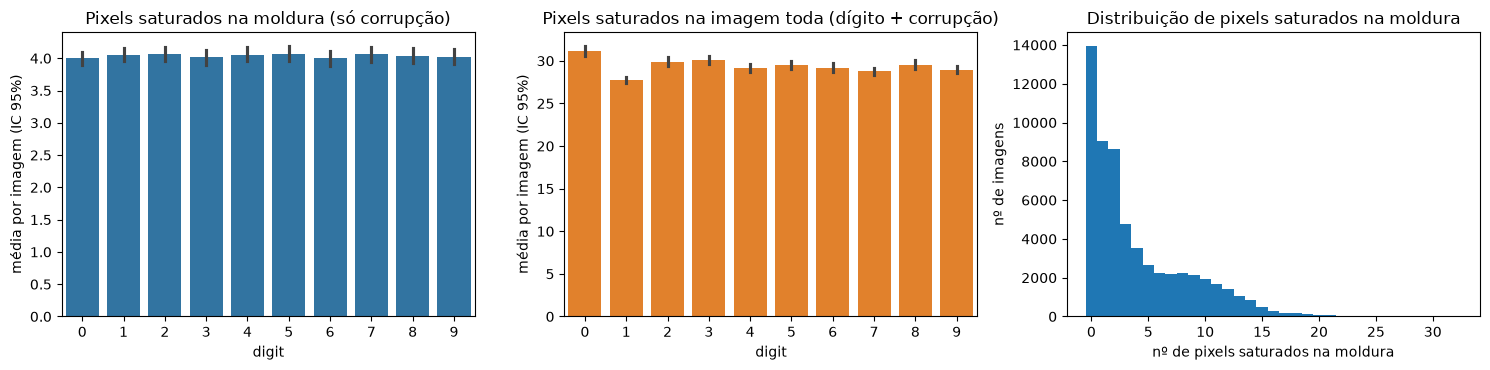

Fração de imagens com algum pixel saturado na moldura: 76.74%


,frame_mean,frame_any,sat_total_mean
digit,,,
0,3.998,0.773,31.167
1,4.056,0.765,27.759
2,4.064,0.772,29.919
3,4.016,0.776,30.108
4,4.056,0.774,29.183
5,4.066,0.768,29.498
6,3.997,0.764,29.215
7,4.060,0.764,28.785
8,4.040,0.761,29.536


In [9]:
# (4) A corrupção depende da classe?
# Na moldura não há dígito, então o nº de pixels saturados ali mede só a corrupção.
frame_hits = sat[:, frame_mask].sum(axis=1)
sat_per_img = sat.reshape(len(sat), -1).sum(axis=1)

per_class = pd.DataFrame({"digit": y_full, "frame_hits": frame_hits, "sat_total": sat_per_img})
summary_by_class = per_class.groupby("digit").agg(
    frame_mean=("frame_hits", "mean"),
    frame_any=("frame_hits", lambda s: (s > 0).mean()),
    sat_total_mean=("sat_total", "mean"),
)

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
sns.barplot(data=per_class, x="digit", y="frame_hits", ax=axs[0], errorbar=("ci", 95), color="tab:blue")
axs[0].set_title("Pixels saturados na moldura (só corrupção)")
axs[0].set_ylabel("média por imagem (IC 95%)")
sns.barplot(data=per_class, x="digit", y="sat_total", ax=axs[1], errorbar=("ci", 95), color="tab:orange")
axs[1].set_title("Pixels saturados na imagem toda (dígito + corrupção)")
axs[1].set_ylabel("média por imagem (IC 95%)")
axs[2].hist(frame_hits, bins=np.arange(0, frame_hits.max() + 2) - 0.5, color="tab:blue")
axs[2].set_title("Distribuição de pixels saturados na moldura")
axs[2].set_xlabel("nº de pixels saturados na moldura"); axs[2].set_ylabel("nº de imagens")
plt.tight_layout()
plt.show()

print(f"Fração de imagens com algum pixel saturado na moldura: {(frame_hits > 0).mean():.2%}")
summary_by_class.round(3)

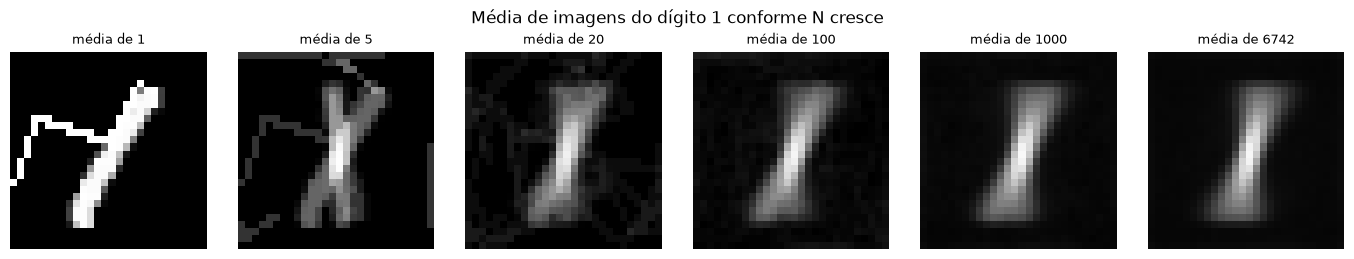

In [10]:
# (5) Por que a média "apaga" a corrupção: a média de N traços em posições aleatórias tende a
# uma constante pequena, enquanto o dígito (sempre no mesmo lugar) se reforça.
digit = 1
idx_digit = np.flatnonzero(y_full == digit)
ns = [1, 5, 20, 100, 1000, len(idx_digit)]
fig, axs = plt.subplots(1, len(ns), figsize=(2.3 * len(ns), 2.6))
for ax, n in zip(axs, ns):
    ax.imshow(imgs_full[idx_digit[:n]].mean(axis=0), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"média de {n}", fontsize=9)
    ax.axis("off")
fig.suptitle(f"Média de imagens do dígito {digit} conforme N cresce")
plt.tight_layout()
plt.show()

> **Question 1.1**
>
> (a) Describe the corruption. Is it random and per-sample, or is it systematic and shared across images? Does it vary across digit classes?
>
> (b) Why does the corruption turn into a faint, nearly uniform background in the per-class mean images? What does that tell you about using mean images to diagnose a corruption?
>
> (c) The corruption is made of strokes, and digits are also made of strokes. Which digits do you expect to be most easily confused with (or by) the corruption?
>
> (d) Are there data regimes where the corruption can affect the model more than in others?
> Hypothesize how these different regimes will affect a model trained on them.

**(a)** A corrupção é **estruturada, mas sorteada por amostra**. Cada imagem recebe uma ou duas linhas retas
finas que formam "quebras" (um zigue-zague), com posição, orientação e comprimento diferentes de imagem para
imagem; não existe um padrão fixo compartilhado (na grade de 12 amostras por classe nenhum traço se repete).
É a corrupção *zigzag* do MNIST-C. Duas propriedades a separam do dígito usando só o treino:

* **É binária e saturada.** Na moldura externa de 1 px, onde o MNIST praticamente não tem tinta, 3,77% dos
  pixels são não nulos e **99,06% deles valem exatamente 255**, sem os valores intermediários do anti-aliasing
  dos traços originais. Cuidado, porém: 255 *não* é sinônimo de corrupção, porque os próprios dígitos também
  saturam (17% de todos os pixels não nulos do treino valem 255, a maioria no miolo dos traços). Por isso
  usamos a moldura, e não "pixel = 255", como sensor da corrupção.
* **Não depende da classe.** O número médio de pixels saturados na moldura fica entre 4,00 e 4,07 para todos
  os dígitos, com intervalos de confiança sobrepostos, e a fração de imagens com algum traço na moldura fica
  entre 76% e 78% em todas as classes. A diferença de pixels saturados na imagem toda entre classes (ex.: o 1
  tem menos) vem do dígito, não da corrupção.

Há ainda um detalhe geométrico: a taxa de saturação na moldura (~4%) é maior que no anel logo interno (~3%),
e é ainda maior nos cantos, o que é consistente com linhas que são cortadas/acumuladas na borda da imagem.

**(b)** Porque a média de muitos traços em posições e orientações aleatórias converge para a *probabilidade*
de cada pixel ser atingido, que é pequena (alguns %) e quase igual em toda a imagem: cerca de
$255 \times 0{,}03 \approx 8$ níveis de cinza, um véu tênue e uniforme. O dígito, ao contrário, está sempre
alinhado no mesmo lugar e se reforça na média (a sequência "média de 1, 5, 20, 100, 1000 imagens" mostra o
traço sumindo enquanto o 1 aparece). A lição é que a imagem média só enxerga o que é **alinhado entre
amostras**: uma corrupção forte mas espacialmente aleatória fica parecendo um ruído de fundo inofensivo. Para
diagnosticá-la é preciso olhar amostras individuais e estatísticas que preservem a estrutura por amostra
(histograma de intensidades, frequência de saturação por pixel, regiões onde só a corrupção existe).

**(c)** Os traços são segmentos retos que se dobram em ângulo, então nossa hipótese era que os dígitos feitos
de segmentos retos fossem os mais confundidos com/pela corrupção: o **1** (um segmento só, com pouca tinta
própria, então um traço extra tem peso comparável ao do dígito), o **7** (dois segmentos em ângulo, quase um
zigue-zague) e o **4**. Como a corrupção só *adiciona* tinta, também esperávamos confusões de um dígito para
outro "com mais traços": 1→7/4, 4→9 (um traço fechando o topo do 4), 3→8/9, 5→6/8. Dígitos com muita tinta e
curvos (0, 8, 6) deveriam ser os menos afetados.

**(d)** Sim. O que importa é quantas vezes cada pixel "contaminado" é visto. No **Full** (60k imagens), cada
pixel é atingido pela corrupção em milhares de imagens de todas as classes, então o efeito médio dele sobre o
rótulo é ~0 e o modelo pode aprender que ele não informa nada. No **Scarce** (1000 imagens), um pixel
periférico é aceso pela corrupção em poucas dezenas de imagens, e com $10 \times 785 = 7850$ parâmetros para
1000 amostras o problema fica separável: o modelo pode usar esses pixels raros para decorar imagens
específicas. Hipótese: o Scarce sofre mais overfitting na corrupção, precisa de mais regularização e terá
estimativas de CV mais ruidosas; o Full precisa de pouca regularização; o Partial fica no meio.

### 1.2 Preprocessing

**(1.0 point)**

Before training, the raw data must be brought into a form suitable for gradient-based optimization.

Two considerations are important here:

1. **Scale.** Raw pixel values are in [0, 255]. Gradient descent is sensitive to the scale of inputs; large input values produce large gradients, which can destabilize training.

2. **Data leakage.** Any statistics used for preprocessing must be computed from the training set only, then applied to all other splits.
Computing statistics on the full dataset, including test data, leaks information about the test distribution into preprocessing and invalidates evaluation.

In [11]:
class Preprocessor:
    """Converte imagens uint8 (N, 28, 28, 1) em vetores float32 (N, 784).

    mode="scale":    x / 255, levando os pixels para [0, 1]. Não estima nada a partir dos dados
                     (a faixa 0-255 é conhecida a priori), então não há como vazar informação.
    mode="standard": z-score por pixel, com média e desvio estimados SOMENTE no conjunto passado
                     a fit(). Implementado para a comparação empírica feita na Parte 3.
    """

    def __init__(self, mode: str = "scale", eps: float = 1e-2) -> None:
        assert mode in ("scale", "standard")
        self.mode = mode
        self.eps = eps
        self.mean_: NDArray[np.float32] | None = None
        self.std_: NDArray[np.float32] | None = None

    @staticmethod
    def _flatten(X: NDArray[Any]) -> NDArray[np.float32]:
        return X.reshape(len(X), -1).astype(np.float32) / 255.0

    def fit(self, X: NDArray[Any]) -> "Preprocessor":
        if self.mode == "standard":
            Xf = self._flatten(X)
            self.mean_ = Xf.mean(axis=0)
            self.std_ = Xf.std(axis=0)
        return self

    def transform(self, X: NDArray[Any]) -> torch.Tensor:
        Xf = self._flatten(X)
        if self.mode == "standard":
            Xf = (Xf - self.mean_) / (self.std_ + self.eps)
        return torch.from_numpy(Xf)


PREPROCESSING = "scale"

# Um pré-processador por regime, ajustado apenas no treino daquele regime; ele mesmo será
# reutilizado (sem reajuste) para transformar os conjuntos de teste na Parte 4.
preprocessors = {name: Preprocessor(PREPROCESSING).fit(X) for name, (X, _) in data_regimes.items()}
train_tensors = {
    name: (preprocessors[name].transform(X), torch.from_numpy(y))
    for name, (X, y) in data_regimes.items()
}

for name, (Xt, yt) in train_tensors.items():
    print(f"{name:8s} X: {tuple(Xt.shape)} {Xt.dtype}, faixa [{Xt.min():.1f}, {Xt.max():.1f}] | y: {tuple(yt.shape)}")

Scarce   X: (1000, 784) torch.float32, faixa [0.0, 1.0] | y: (1000,)
Partial  X: (10000, 784) torch.float32, faixa [0.0, 1.0] | y: (10000,)
Full     X: (60000, 784) torch.float32, faixa [0.0, 1.0] | y: (60000,)


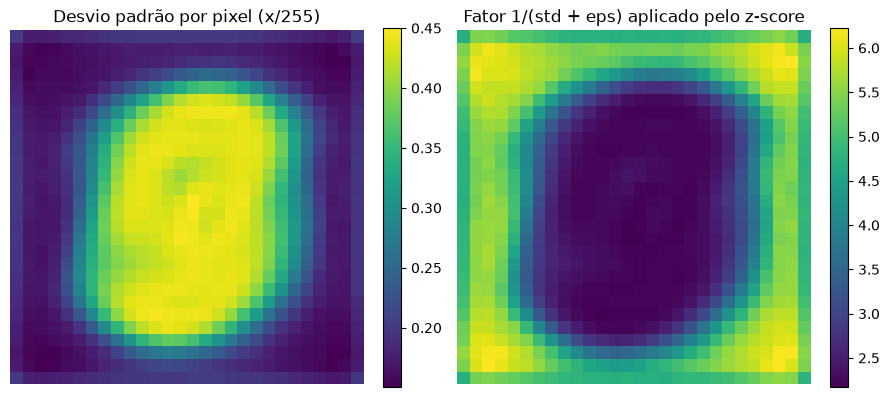

Fator médio na moldura: 5.0x | no centro (8:20, 8:20): 2.3x


In [12]:
# Por que não padronizar por pixel? O z-score divide cada pixel pelo seu desvio padrão.
# Pixels da periferia têm desvio pequeno e, como vimos, ali só existe corrupção:
# a padronização amplificaria justamente as features espúrias.
std_px = X_full.reshape(len(X_full), -1).std(axis=0) / 255.0
amplification = 1.0 / (std_px + 1e-2)

fig, axs = plt.subplots(1, 2, figsize=(9, 4))
im0 = axs[0].imshow(std_px.reshape(28, 28), cmap="viridis")
axs[0].set_title("Desvio padrão por pixel (x/255)")
plt.colorbar(im0, ax=axs[0], fraction=0.046)
im1 = axs[1].imshow(amplification.reshape(28, 28), cmap="viridis")
axs[1].set_title("Fator 1/(std + eps) aplicado pelo z-score")
plt.colorbar(im1, ax=axs[1], fraction=0.046)
for ax in axs:
    ax.axis("off")
plt.tight_layout()
plt.show()

print(f"Fator médio na moldura: {amplification[frame_mask.ravel()].mean():.1f}x | "
      f"no centro (8:20, 8:20): {amplification.reshape(28, 28)[8:20, 8:20].mean():.1f}x")

> **Question 1.2**
>
> Describe the preprocessing choices made above. What strategy have you chosen, and why?

Escolhemos **dividir os pixels por 255**, levando-os para $[0, 1]$, e achatar cada imagem em um vetor de 784
posições (classe `Preprocessor`, modo `"scale"`).

* **Escala.** $[0,1]$ deixa os gradientes da regressão logística em uma escala em que um passo fixo
  ($\text{lr} = 0{,}5$) é estável em todos os regimes.
* **Vazamento.** A faixa 0-255 é conhecida a priori, então essa transformação não estima *nada* dos dados
  e não há como vazar informação do teste ou dos folds de validação. Mesmo assim a implementação segue o
  padrão `fit` no treino → `transform` no resto: há um pré-processador por regime, ele é reajustado dentro de
  cada fold na validação cruzada e é reutilizado sem reajuste nos conjuntos de teste.
* **Por que não padronizar por pixel (z-score)?** O desvio padrão é pequeno justamente na periferia, onde
  só existe corrupção, então o z-score multiplicaria esses pixels por ~5,0× (contra ~2,3× no centro),
  **amplificando as features espúrias**. Também tiraria o significado do zero (fundo preto), que deixaria de
  ser zero. A verificação empírica na Parte 3 confirma: no regime Partial sem regularização, a CV dá
  $0{,}8243 \pm 0{,}0062$ com `x/255` contra $0{,}8025 \pm 0{,}0074$ com z-score ajustado dentro dos folds.
* Manter o zero como zero também deixa os pesos interpretáveis como "contribuição por unidade de tinta" e faz
  com que pixels nunca acesos no treino não recebam gradiente (com inicialização em zero, seus pesos ficam
  exatamente em 0).

---

## Part 2. Multinomial Logistic Regression

### 2.1 The model

Multinomial logistic regression (also called softmax regression) is the natural extension of binary logistic regression to $K > 2$ classes.

Given an input $\mathbf{x} \in \mathbb{R}^d$, the model computes a score (logit) for each class $k$:

$$z_k = \mathbf{w}_k^\top \mathbf{x} + b_k$$

Each logit is an unconstrained real number, in order to transform these values into
probabilities, where $p_k \geq 0$ and $\sum_k p_k = 1$, the softmax function
is used:

$$P(y = k \mid \mathbf{x}) = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}$$

Training minimizes the **cross-entropy loss**, which is the negative log-likelihood of the true class under this distribution:

$$\mathcal{L}(\mathbf{W}, \mathbf{b}) = -\frac{1}{N} \sum_{i=1}^{N} \log P(y_i \mid \mathbf{x}_i)$$

For MNIST with $d = 784$ pixels and $K = 10$ classes, the weight matrix $\mathbf{W} \in \mathbb{R}^{10 \times 784}$ has one row per class. Each row $\mathbf{w}_k$ can be reshaped into a 28×28 image and visualized directly: positive values indicate pixels whose brightness increases the log-odds of class $k$, whereas negative values suppress it.
This direct interpretability is one reason we use a linear model here.

### 2.2 Regularization

Standard cross-entropy minimization has no preference over the parameter space.
With enough capacity, or with corrupted data that contains spurious features, the model can assign large weights to uninformative or noisy pixels if doing so reduces training loss.

Regularization considers an additional assumption over the nature of the learned weights,
adding a penalty on the weights to the loss:

$$\mathcal{L}_{\text{reg}} = \mathcal{L} + \lambda \cdot \Omega(\mathbf{W})$$

Two common choices for $\Omega$:

- **L2 (Ridge):** $\Omega(\mathbf{W}) = \|\mathbf{W}\|_2^2 = \sum_{k,j} w_{kj}^2$. Penalizes large weights uniformly, where all weights shrink toward zero but none are forced exactly to zero.
In PyTorch's optimizers, L2 is implemented as `weight_decay`.

- **L1 (Lasso):** $\Omega(\mathbf{W}) = \|\mathbf{W}\|_1 = \sum_{k,j} |w_{kj}|$. Penalizes the sum of absolute values, producing sparse solutions where many weights are driven to exactly zero.

The hyperparameter $\lambda \geq 0$ controls the strength of regularization.
$\lambda = 0$ recovers the unregularized problem.

**(2.0 point)**

Implement the Multinomial Logistic Regression model using PyTorch's nn.Module
for the linear model (image as input and logits as outputs), and SGD with both
L1 and L2 regularization methods.

In [13]:
# Hiperparâmetros de otimização, fixos para todos os experimentos (o objeto de estudo é lambda).
# Com x em [0, 1], lr = 0.5 é estável em full-batch (a direção de maior curvatura de X^T X, a
# imagem média, não altera o softmax). Usamos a versão acelerada (FISTA) do gradiente: com
# 500 iterações os modelos regularizados convergem (testamos 500 vs. 1500 iterações e os pesos
# não mudam). Com GD simples, 500 iterações param o modelo longe do ótimo, o que funciona como
# regularização implícita (early stopping) e mascararia o efeito de lambda; esse efeito é
# medido explicitamente na Parte 4.
LR = 0.5
N_ITER = 500


class LinearModel(nn.Module):
    """Regressão logística multinomial: imagem -> 10 logits (z = W x + b)."""

    def __init__(self, n_features: int = 28 * 28, n_classes: int = 10) -> None:
        super().__init__()
        self.linear = nn.Linear(n_features, n_classes)
        # Inicialização em zero: o problema é convexo (não há simetria a quebrar) e assim um pixel
        # que nunca recebe gradiente fica exatamente em 0, em vez de guardar o ruído do init aleatório.
        nn.init.zeros_(self.linear.weight)
        nn.init.zeros_(self.linear.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear(x.flatten(start_dim=1))

    @property
    def weights(self) -> NDArray[np.float32]:
        return self.linear.weight.detach().cpu().numpy()


def accuracy(logits: torch.Tensor, y: torch.Tensor) -> float:
    """Fraction of correctly predicted samples."""
    y_pred = logits.argmax(dim=-1)
    return (y == y_pred).float().mean().item()


def soft_threshold(w: torch.Tensor, threshold: float) -> torch.Tensor:
    """Operador proximal da norma L1: encolhe |w| por `threshold` e zera o que cruzar o zero."""
    return torch.sign(w) * torch.clamp(w.abs() - threshold, min=0.0)


def train(
    model: nn.Module,
    X: torch.Tensor,
    y: torch.Tensor,
    n_iter: int,
    lr: float = 0.1,
    l1: float = 0.0,
    l2: float = 0.0,
    accelerated: bool = True,
) -> list[float]:
    """
    Train a model using full-batch SGD with L1/L2 regularization.

    Minimiza  CE(W, b) + l1 * ||W||_1 + l2 * ||W||_2^2  (o viés b não é regularizado).

    * L2: via `weight_decay`. O PyTorch soma weight_decay * w ao gradiente, que é o gradiente
      de (weight_decay / 2) * ||w||^2; logo usamos weight_decay = 2 * l2 para bater com a fórmula.
    * L1: passo proximal (soft-thresholding, i.e. ISTA) após cada passo de gradiente. Somar
      l1 * |W| à perda e usar o subgradiente faz os pesos oscilarem em torno de zero sem nunca
      zerá-los; o operador proximal zera exatamente os pesos com |w| <= lr * l1.
    * accelerated=True: extrapolação de Nesterov sobre os iterados (FISTA). Ao contrário do
      momentum do otimizador, que acumula gradientes e "desfaz" os zeros do passo proximal,
      a extrapolação usa a diferença entre iterados já limiarizados. Com accelerated=False é
      o gradiente descendente simples (ISTA).

    Returns the list of per-iteration training losses (objetivo regularizado completo,
    avaliado no ponto em que o gradiente é calculado).
    """
    W, b = model.linear.weight, model.linear.bias
    optimizer = optim.SGD(
        [{"params": [W], "weight_decay": 2 * l2},
         {"params": [b], "weight_decay": 0.0}],
        lr=lr,
    )
    loss_fn = nn.CrossEntropyLoss()

    model.train()
    losses = []
    prev = [W.detach().clone(), b.detach().clone()]  # iterados anteriores (FISTA)
    t = 1.0
    for _ in range(n_iter):
        optimizer.zero_grad()
        ce = loss_fn(model(X), y)
        ce.backward()
        with torch.no_grad():
            losses.append(ce.item() + l1 * W.abs().sum().item() + l2 * W.pow(2).sum().item())
        optimizer.step()
        with torch.no_grad():
            if l1 > 0:
                W.copy_(soft_threshold(W, lr * l1))
            if accelerated:
                t_next = (1 + np.sqrt(1 + 4 * t * t)) / 2
                beta = (t - 1) / t_next
                for param, p_prev in zip((W, b), prev):
                    current = param.detach().clone()
                    param.add_(beta * (current - p_prev))
                    p_prev.copy_(current)
                t = t_next
    if accelerated:  # devolve o último iterado (limiarizado), não o ponto extrapolado
        with torch.no_grad():
            W.copy_(prev[0])
            b.copy_(prev[1])
    return losses


def fit_model(
    X: torch.Tensor, y: torch.Tensor, l1: float = 0.0, l2: float = 0.0, accelerated: bool = True
) -> tuple[LinearModel, list[float]]:
    model = LinearModel(n_features=X.shape[1])
    losses = train(model, X, y, N_ITER, lr=LR, l1=l1, l2=l2, accelerated=accelerated)
    return model, losses


@torch.no_grad()
def predict_logits(model: nn.Module, X: torch.Tensor) -> torch.Tensor:
    model.eval()
    return model(X)


def sparsity(model: LinearModel, tol: float = 1e-3) -> float:
    """Fração de pesos com |w| < tol."""
    return float((np.abs(model.weights) < tol).mean())


def frame_weight_share(model: LinearModel) -> float:
    """Fração da massa |W| que está na moldura de 1 px, onde o treino contém essencialmente só corrupção.
    A moldura tem 108/784 = 13.8% dos pixels."""
    w = np.abs(model.weights)
    return float(w[:, frame_mask.ravel()].sum() / w.sum())


def weight_stats(model: LinearModel) -> dict[str, float]:
    w = model.weights
    return {
        "||W||_2": float(np.linalg.norm(w)),
        "max|w|": float(np.abs(w).max()),
        "sparsity (|w|<1e-3)": sparsity(model),
        "massa |W| na moldura": frame_weight_share(model),
    }

### 2.3 Baseline mode

**(2.0 points)**

Train a unregularized model on each training set and observe the training loss
per iteration on each model during training.

To diagnose and understand what the trained model have learned, we visualize the
learned weights as a heatmap.

Scarce   | acurácia de treino 1.0000 | perda final 0.0004 | 2.6s


Partial  | acurácia de treino 0.9991 | perda final 0.0337 | 3.2s


Full     | acurácia de treino 0.9078 | perda final 0.3103 | 27.7s


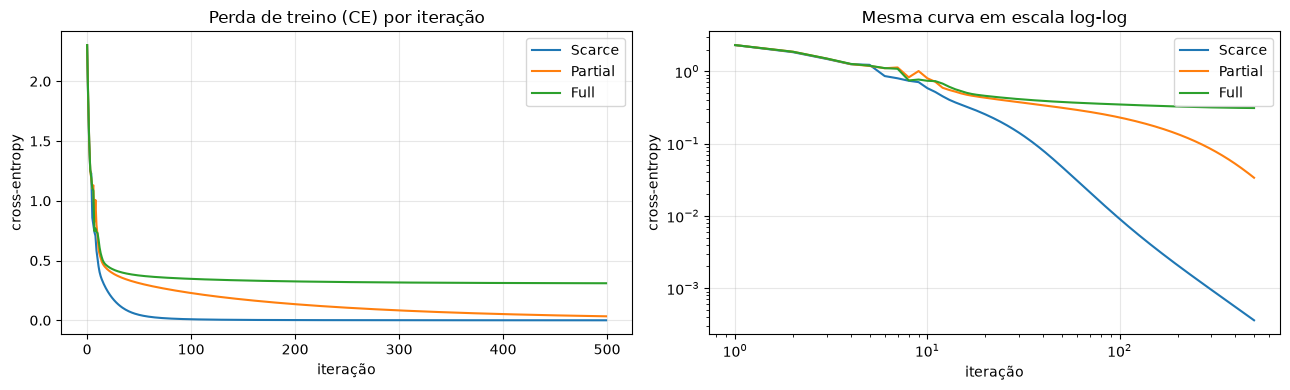

In [14]:
baseline_models: dict[str, LinearModel] = {}
baseline_losses: dict[str, list[float]] = {}

for name, (Xt, yt) in train_tensors.items():
    t0 = time.time()
    baseline_models[name], baseline_losses[name] = fit_model(Xt, yt)
    train_acc = accuracy(predict_logits(baseline_models[name], Xt), yt)
    print(f"{name:8s} | acurácia de treino {train_acc:.4f} | perda final {baseline_losses[name][-1]:.4f} | {time.time() - t0:.1f}s")

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for name, losses in baseline_losses.items():
    axs[0].plot(losses, label=name)
    axs[1].loglog(np.arange(1, len(losses) + 1), losses, label=name)
axs[0].set_title("Perda de treino (CE) por iteração")
axs[1].set_title("Mesma curva em escala log-log")
for ax in axs:
    ax.set_xlabel("iteração"); ax.set_ylabel("cross-entropy"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()

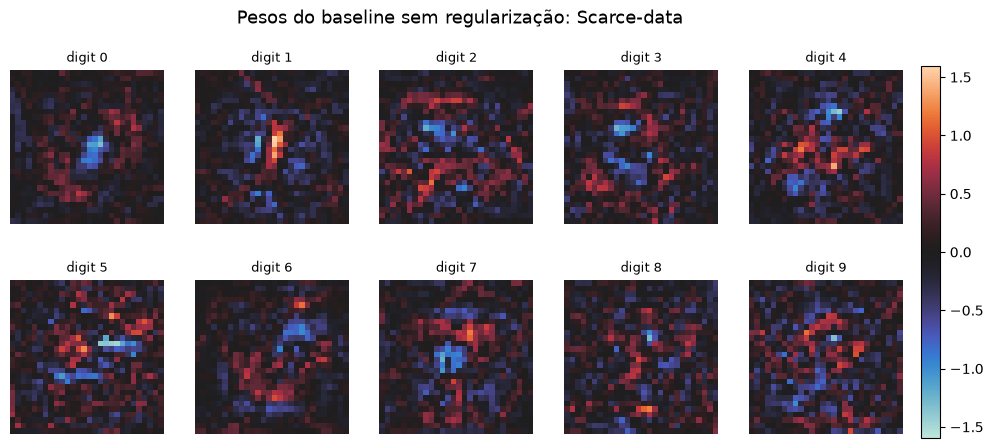

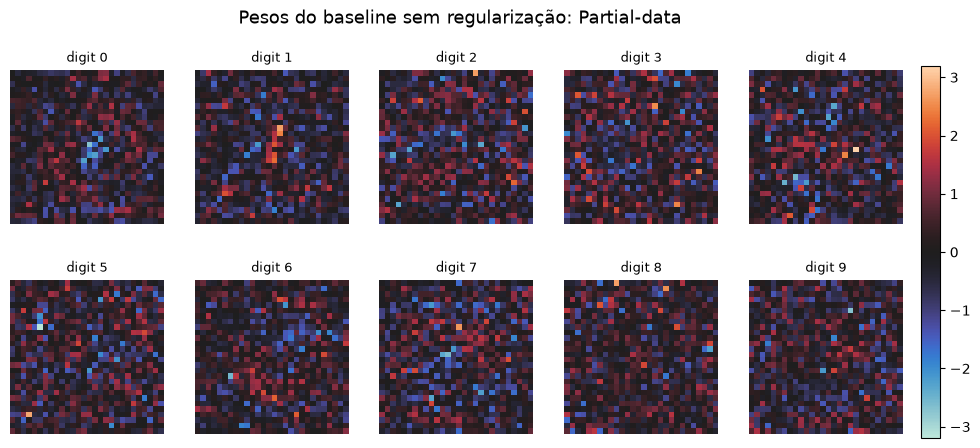

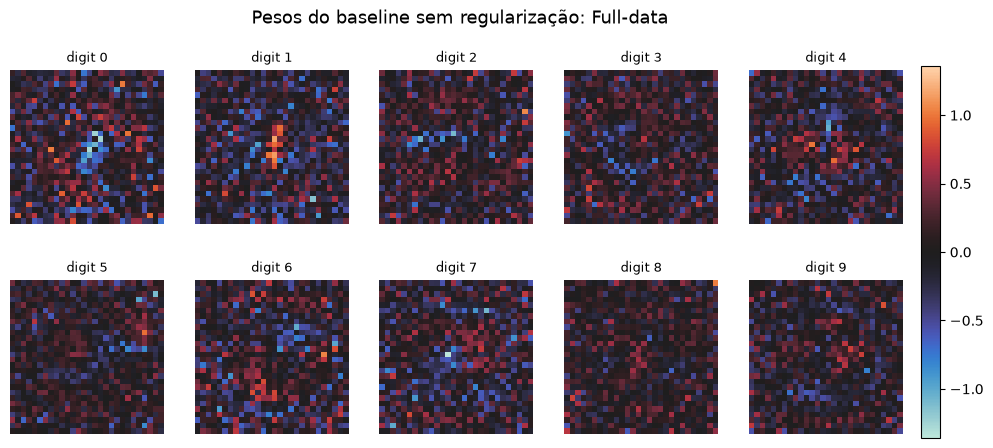

In [15]:
# Visualize learned weight images, one per digit class.
# Use a diverging colormap: red = positive weight (pixel increases log-odds),
# blue = negative weight (pixel suppresses log-odds).
# Alteração: escala simétrica em torno de 0 (senão o "zero" do mapa divergente fica deslocado)
# e uma barra de cores, para que a magnitude possa ser comparada entre modelos.

def plot_weights(weights: NDArray[np.float32], title: str) -> None:
    fig, axs = plt.subplots(2, 5, figsize=(12, 5))
    fig.suptitle(title, fontsize=13)
    vmax = np.abs(weights).max()

    for digit in range(10):
        ax = axs[digit // 5, digit % 5]
        im = ax.imshow(weights[digit].reshape(28, 28), cmap="icefire", vmin=-vmax, vmax=vmax)
        ax.set_title(f"digit {digit}", fontsize=9)
        ax.axis("off")

    fig.colorbar(im, ax=axs, fraction=0.02, pad=0.02)
    plt.show()


def plot_weight_rows(models: dict[str, LinearModel], title: str) -> None:
    """Uma linha por modelo, uma coluna por dígito; escala simétrica própria de cada linha."""
    fig, axs = plt.subplots(len(models), 10, figsize=(16, 1.75 * len(models) + 0.6), squeeze=False)
    for row, (label, model) in enumerate(models.items()):
        w = model.weights
        vmax = np.abs(w).max()
        for digit in range(10):
            ax = axs[row, digit]
            im = ax.imshow(w[digit].reshape(28, 28), cmap="icefire", vmin=-vmax, vmax=vmax)
            ax.set_xticks([]); ax.set_yticks([])
            if row == 0:
                ax.set_title(f"digit {digit}", fontsize=9)
        axs[row, 0].set_ylabel(label, fontsize=9)
        fig.colorbar(im, ax=axs[row, :], fraction=0.01, pad=0.01)
    fig.suptitle(title, fontsize=13)
    plt.show()


for name, model in baseline_models.items():
    plot_weights(model.weights, f"Pesos do baseline sem regularização: {name}-data")

In [16]:
pd.DataFrame({name: weight_stats(model) for name, model in baseline_models.items()}).T.round(4)

,||W||_2,max|w|,sparsity (|w|<1e-3),massa |W| na moldura
Scarce,27.5538,1.5953,0.0029,0.0947
Partial,64.8049,3.1941,0.0014,0.1223
Full,26.7723,1.3591,0.0020,0.1384


> **Question 2.3**
>
> Inspect the weight images for each baseline model. How do you explain the
> weight values in the heatmap, and what patterns do they show?
>
> Compare between the model, how are they different?

**Treino.** Com λ = 0, o modelo do **Scarce** chega a 100% de acurácia de treino e perda $4\times10^{-4}$: os
dados são linearmente separáveis, então não existe mínimo finito e a perda só cai porque $\|W\|$ cresce
(a curva log-log é uma reta descendente). O **Partial** chega a 99,9% e a perda ainda está caindo após 500
iterações. O **Full** estabiliza em 90,8% e perda 0,31: com 60k imagens ruidosas o problema não é separável e
existe um ótimo finito.

**Pesos.** As imagens do baseline têm uma textura de **sal e pimenta**: pixels isolados com pesos grandes,
positivos ou negativos, espalhados por toda a imagem, inclusive na periferia; os "moldes" dos dígitos ficam por
baixo, fracos (o 0 com o centro negativo e o anel positivo, o 1 com a barra vertical positiva e as laterais
negativas). A explicação é a seguinte: um pixel aceso em poucas imagens de treino (tipicamente pela corrupção,
na periferia) só recebe gradiente dessas imagens. Aumentar o peso dele ajuda a acertar exatamente essas
imagens sem custo nenhum nas outras, em que ele vale 0. Sem penalidade, nada impede esses pesos de crescer, e
as features **raras** acabam com os pesos **maiores**. Quantitativamente, a fração da massa $|W|$ na moldura
de 1 px (onde só há corrupção) é 13,8% no Full, idêntica à fração de pixels da moldura (108/784): o modelo
dá tanta importância a pixels que só contêm corrupção quanto a um pixel médio.

**Comparação entre regimes.**

| | $\|W\|_2$ | max $|w|$ | massa na moldura |
|---|---|---|---|
| Scarce | 27,6 | 1,60 | 9,5% |
| Partial | **64,8** | **3,19** | 12,2% |
| Full | 26,8 | 1,36 | 13,8% |

O pior caso é o **Partial**, e não o Scarce: seus pesos são quase puro ruído, com norma 2,4× maior. Isso
contraria a nossa hipótese da 1.1(d). Interpretamos assim:

* No **Scarce**, com 1000 amostras e 7850 parâmetros, o conjunto é separado facilmente. Com inicialização em
  zero, o gradiente mantém $W$ no espaço gerado pelas 1000 imagens de treino (cada linha de $W$ é uma
  combinação linear delas), e em dados separáveis o gradiente converge para a direção de margem máxima, um
  viés implícito parecido com L2. Por isso os moldes ainda são reconhecíveis.
* O **Partial** está perto do limiar de interpolação: 10k imagens *quase* separáveis. Para acertar os últimos
  exemplos difíceis, o otimizador precisa de pesos enormes em pixels raros.
* No **Full**, o excesso de dados não deixa decorar, mas a estimativa dos pesos de pixels raros continua com
  variância alta, daí o ruído residual.

Observação: com gradiente descendente simples (sem aceleração), os mesmos 500 passos param muito antes desse
ponto e o baseline sai bem mais "regularizado". Medimos esse efeito de early stopping na Parte 4.

---

## Part 3. Regularization

**(2.0 points)**

We now introduce regularization and sweep over $\lambda$ values for both L1 and L2 penalties.

Your **only decision criterion** in this part is cross-validation accuracy computed on the corrupted training data, exactly what you would have in a real scenario without access to a clean or differently corrupted test set.

For each configuration (data regime x reg type x $\lambda$), use K-fold cross-validation to estimate validation accuracy (report mean **and** standard deviation across folds).
Then, for each regularizer, **select the best $\lambda$** by CV and train a final model on the full training set of that regime.

Also train and store one model for **every** $\lambda$ of the grid on the Full-data regime: they will not be used for selection, only for the diagnostic plots of Part 4.

> **Decision task** Report, per regularizer and data regimes, which $\lambda$ you selected and why.
Inspect the weight images of your chosen models and describe what you observe.

In [17]:
K_FOLDS = 5
LAMBDAS = {
    "L2": [1e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1],
    "L1": [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2],
}


def reg_kwargs(reg: str, lam: float) -> dict[str, float]:
    return {"L1": {"l1": lam}, "L2": {"l2": lam}}.get(reg, {})


def cross_validate(
    X: NDArray[Any], y: NDArray[Any], l1: float = 0.0, l2: float = 0.0,
    k: int = K_FOLDS, preprocessing: str = PREPROCESSING,
) -> NDArray[np.float64]:
    """K-fold estratificado. O pré-processamento é ajustado DENTRO de cada fold, só com o fold de
    treino. As partições são as mesmas para toda configuração (mesma semente), então diferenças
    entre lambdas são comparações pareadas."""
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    scores = []
    for tr_idx, va_idx in skf.split(np.zeros(len(y)), y):
        prep = Preprocessor(preprocessing).fit(X[tr_idx])
        X_tr, X_va = prep.transform(X[tr_idx]), prep.transform(X[va_idx])
        y_tr, y_va = torch.from_numpy(y[tr_idx]), torch.from_numpy(y[va_idx])
        model, _ = fit_model(X_tr, y_tr, l1=l1, l2=l2)
        scores.append(accuracy(predict_logits(model, X_va), y_va))
    return np.array(scores)

Antes da varredura, uma verificação empírica da escolha da Questão 1.2: comparamos por CV (regime Partial,
sem regularização) a escala fixa `x/255` com a padronização por pixel ajustada dentro de cada fold.

In [18]:
X_part, y_part = data_regimes["Partial"]
for mode in ["scale", "standard"]:
    folds = cross_validate(X_part, y_part, preprocessing=mode)
    print(f"{mode:9s}: CV = {folds.mean():.4f} ± {folds.std(ddof=1):.4f}  folds = {np.round(folds, 4)}")

scale    : CV = 0.8243 ± 0.0062  folds = [0.8215 0.821  0.8185 0.834  0.8265]


standard : CV = 0.8025 ± 0.0074  folds = [0.7985 0.7975 0.796  0.8075 0.813 ]


In [19]:
cv_rows = []
for name, (X, y) in data_regimes.items():
    configs = [("none", 0.0)] + [(reg, lam) for reg, lams in LAMBDAS.items() for lam in lams]
    t0 = time.time()
    for reg, lam in configs:
        folds = cross_validate(X, y, **reg_kwargs(reg, lam))
        cv_rows.append({"regime": name, "reg": reg, "lam": lam,
                        "cv_mean": folds.mean(), "cv_std": folds.std(ddof=1), "folds": folds})
    print(f"{name:8s}: {len(configs)} configurações x {K_FOLDS} folds em {time.time() - t0:.0f}s")

cv_df = pd.DataFrame(cv_rows)
regime_order = list(data_regimes)

cv_table = cv_df.assign(cv=lambda d: d.cv_mean.map("{:.4f}".format) + " ± " + d.cv_std.map("{:.4f}".format))
cv_table.pivot_table(index=["reg", "lam"], columns="regime", values="cv", aggfunc="first")[regime_order]

Scarce  : 17 configurações x 5 folds em 60s


Partial : 17 configurações x 5 folds em 323s


Full    : 17 configurações x 5 folds em 1928s


regime                 Scarce          Partial             Full
reg  lam                                                       
L1   0.00001  0.8190 ± 0.0216  0.8265 ± 0.0053  0.8691 ± 0.0018
     0.00003  0.8220 ± 0.0175  0.8300 ± 0.0069  0.8755 ± 0.0024
     0.00010  0.8190 ± 0.0216  0.8405 ± 0.0069  0.8812 ± 0.0023
     0.00030  0.8120 ± 0.0239  0.8614 ± 0.0118  0.8803 ± 0.0015
     0.00100  0.8020 ± 0.0110  0.8599 ± 0.0116  0.8698 ± 0.0022
     0.00300  0.7830 ± 0.0205  0.8332 ± 0.0103  0.8440 ± 0.0015
     0.01000  0.7450 ± 0.0366  0.7777 ± 0.0097  0.7840 ± 0.0023
     0.03000  0.5190 ± 0.0216  0.5028 ± 0.0094  0.4980 ± 0.0031
L2   0.00001  0.8260 ± 0.0270  0.8257 ± 0.0058  0.8673 ± 0.0014
     0.00010  0.8220 ± 0.0268  0.8470 ± 0.0084  0.8791 ± 0.0021
     0.00030  0.8250 ± 0.0235  0.8591 ± 0.0094  0.8830 ± 0.0020
     0.00100  0.8260 ± 0.0207  0.8704 ± 0.0101  0.8837 ± 0.0016
     0.00300  0.8260 ± 0.0216  0.8728 ± 0.0106  0.8794 ± 0.0025
     0.01000  0.8300 ± 0.0274  0.8553 ± 0.0107  0.8639 ± 0.0049
     0.03000  0.8180 ± 0.0370  0.8141 ± 0.0105  0.8307 ± 0.0046
     0.10000  0.5450 ± 0.0573  0.4435 ± 0.1084  0.4755 ± 0.0774
none 0.00000  0.8250 ± 0.0215  0.8243 ± 0.0062  0.8645 ± 0.0014

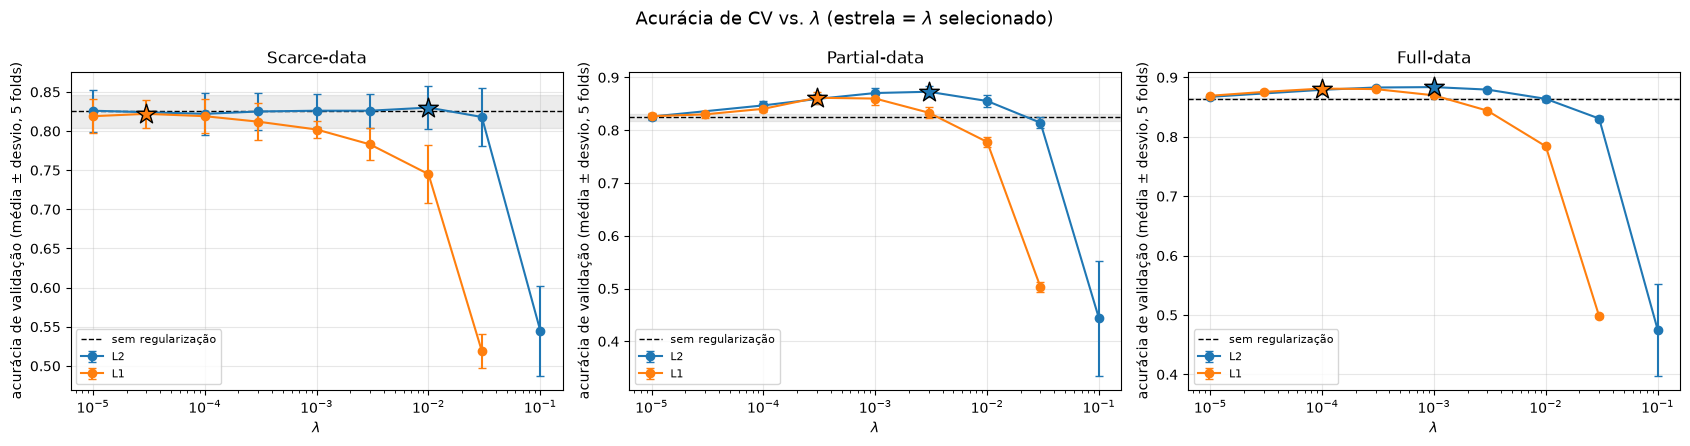

In [20]:
colors = {"none": "black", "L2": "tab:blue", "L1": "tab:orange"}

fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, name in zip(axs, regime_order):
    d = cv_df[cv_df.regime == name]
    base = d[d.reg == "none"].iloc[0]
    ax.axhline(base.cv_mean, color=colors["none"], ls="--", lw=1, label="sem regularização")
    ax.axhspan(base.cv_mean - base.cv_std, base.cv_mean + base.cv_std, color="gray", alpha=0.15)
    for reg in LAMBDAS:
        r = d[d.reg == reg]
        ax.errorbar(r.lam, r.cv_mean, yerr=r.cv_std, marker="o", capsize=3, color=colors[reg], label=reg)
        best_row = r.loc[r.cv_mean.idxmax()]
        ax.scatter(best_row.lam, best_row.cv_mean, s=220, marker="*", color=colors[reg], edgecolor="k", zorder=5)
    ax.set_xscale("log")
    ax.set_xlabel(r"$\lambda$")
    ax.set_ylabel("acurácia de validação (média ± desvio, 5 folds)")
    ax.set_title(f"{name}-data")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.suptitle(r"Acurácia de CV vs. $\lambda$ (estrela = $\lambda$ selecionado)", fontsize=13)
plt.tight_layout()
plt.show()

In [21]:
# Seleção: maior acurácia média de CV por (regime, regularizador).
# Para a Questão 3(a), comparamos o melhor lambda com seus vizinhos na grade: diferença das médias,
# desvio entre folds e desvio da diferença PAREADA (mesmos folds para todos os lambdas).
selected: dict[tuple[str, str], float] = {}
sel_rows = []
for name in regime_order:
    for reg, lams in LAMBDAS.items():
        r = cv_df[(cv_df.regime == name) & (cv_df.reg == reg)].reset_index(drop=True)
        i = int(r.cv_mean.idxmax())
        best_row = r.loc[i]
        selected[(name, reg)] = best_row.lam
        for j in (i - 1, i + 1):
            if 0 <= j < len(r):
                diff = best_row.folds - r.loc[j].folds
                sel_rows.append({
                    "regime": name, "reg": reg, "λ selecionado": f"{best_row.lam:g}",
                    "CV selecionado": f"{best_row.cv_mean:.4f} ± {best_row.cv_std:.4f}",
                    "λ vizinho": f"{r.loc[j].lam:g}",
                    "CV vizinho": f"{r.loc[j].cv_mean:.4f} ± {r.loc[j].cv_std:.4f}",
                    "Δ média": diff.mean(),
                    "desvio do Δ pareado": diff.std(ddof=1),
                })

pd.DataFrame(sel_rows).round(4)

,regime,reg,λ selecionado,CV selecionado,λ vizinho,CV vizinho,Δ média,desvio do Δ pareado
0,Scarce,L2,0.01,0.8300 ± 0.0274,0.003,0.8260 ± 0.0216,0.0040,0.0167
1,Scarce,L2,0.01,0.8300 ± 0.0274,0.03,0.8180 ± 0.0370,0.0120,0.0135
2,Scarce,L1,3e-05,0.8220 ± 0.0175,1e-05,0.8190 ± 0.0216,0.0030,0.0057
3,Scarce,L1,3e-05,0.8220 ± 0.0175,0.0001,0.8190 ± 0.0216,0.0030,0.0045
4,Partial,L2,0.003,0.8728 ± 0.0106,0.001,0.8704 ± 0.0101,0.0024,0.0014
5,Partial,L2,0.003,0.8728 ± 0.0106,0.01,0.8553 ± 0.0107,0.0175,0.0063
6,Partial,L1,0.0003,0.8614 ± 0.0118,0.0001,0.8405 ± 0.0069,0.0209,0.0071
7,Partial,L1,0.0003,0.8614 ± 0.0118,0.001,0.8599 ± 0.0116,0.0015,0.0042
8,Full,L2,0.001,0.8837 ± 0.0016,0.0003,0.8830 ± 0.0020,0.0007,0.0014
9,Full,L2,0.001,0.8837 ± 0.0016,0.003,0.8794 ± 0.0025,0.0042,0.0010


In [22]:
# Modelos finais: cada regime retreinado em TODO o seu conjunto de treino com o lambda selecionado.
# Além disso, um modelo por lambda da grade no regime Full (diagnóstico da Parte 4).
# O baseline (lambda = 0) já foi treinado na Parte 2 com a mesma configuração e é reaproveitado.
X_full_t, y_full_t = train_tensors["Full"]

t0 = time.time()
full_grid_models: dict[tuple[str, float], LinearModel] = {("none", 0.0): baseline_models["Full"]}
for reg, lams in LAMBDAS.items():
    for lam in lams:
        full_grid_models[(reg, lam)], _ = fit_model(X_full_t, y_full_t, **reg_kwargs(reg, lam))
print(f"{len(full_grid_models) - 1} modelos da grade (Full) treinados em {time.time() - t0:.0f}s")

final_models: dict[str, dict[str, LinearModel]] = {}
for name in regime_order:
    Xt, yt = train_tensors[name]
    final_models[name] = {"none": baseline_models[name]}
    for reg in LAMBDAS:
        lam = selected[(name, reg)]
        if name == "Full":
            final_models[name][reg] = full_grid_models[(reg, lam)]
        else:
            final_models[name][reg], _ = fit_model(Xt, yt, **reg_kwargs(reg, lam))

final_stats = pd.DataFrame(
    {(name, kind): weight_stats(model) for name, models in final_models.items() for kind, model in models.items()}
).T.round(4)
final_stats.insert(0, "λ", [f"{selected.get(key, 0.0):g}" for key in final_stats.index])
final_stats

16 modelos da grade (Full) treinados em 459s


λ  ||W||_2  max|w|  sparsity (|w|<1e-3)  \
Scarce  none       0  27.5538  1.5953               0.0029   
        L2      0.01   4.9509  0.2931               0.0237   
        L1     3e-05  21.3474  1.7337               0.3742   
Partial none       0  64.8049  3.1941               0.0014   
        L2     0.003   6.5495  0.4037               0.0186   
        L1    0.0003  14.9242  1.6052               0.7818   
Full    none       0  26.7723  1.3591               0.0020   
        L2     0.001   8.0196  0.5573               0.0162   
        L1    0.0001  12.9975  1.1366               0.6210   

              massa |W| na moldura  
Scarce  none                0.0947  
        L2                  0.0710  
        L1                  0.0567  
Partial none                0.1223  
        L2                  0.0580  
        L1                  0.0305  
Full    none                0.1384  
        L2                  0.0514  
        L1                  0.0333

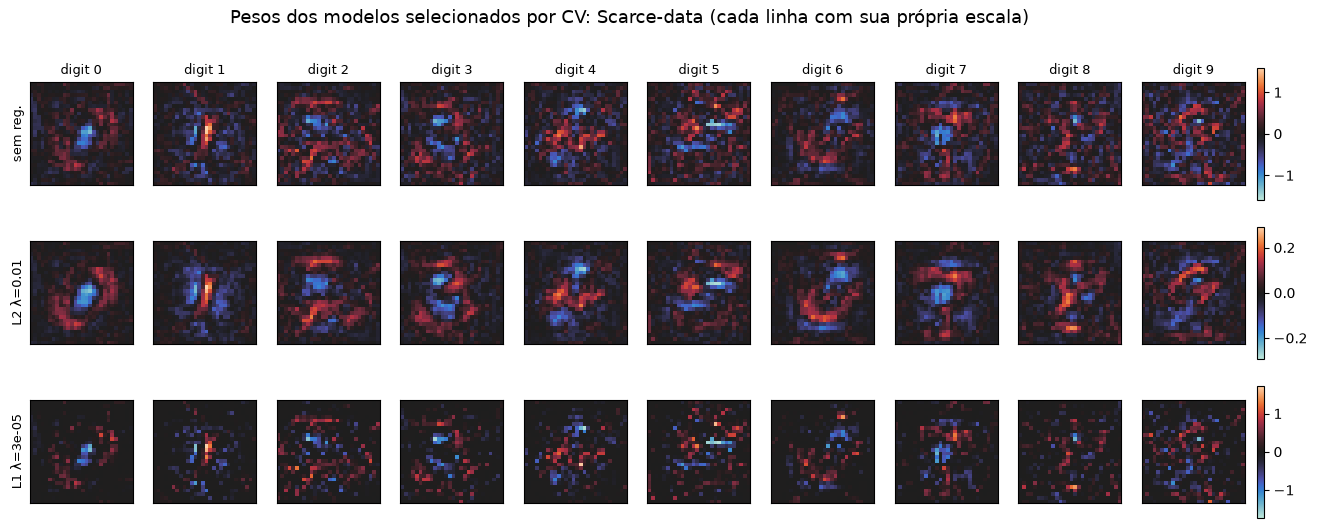

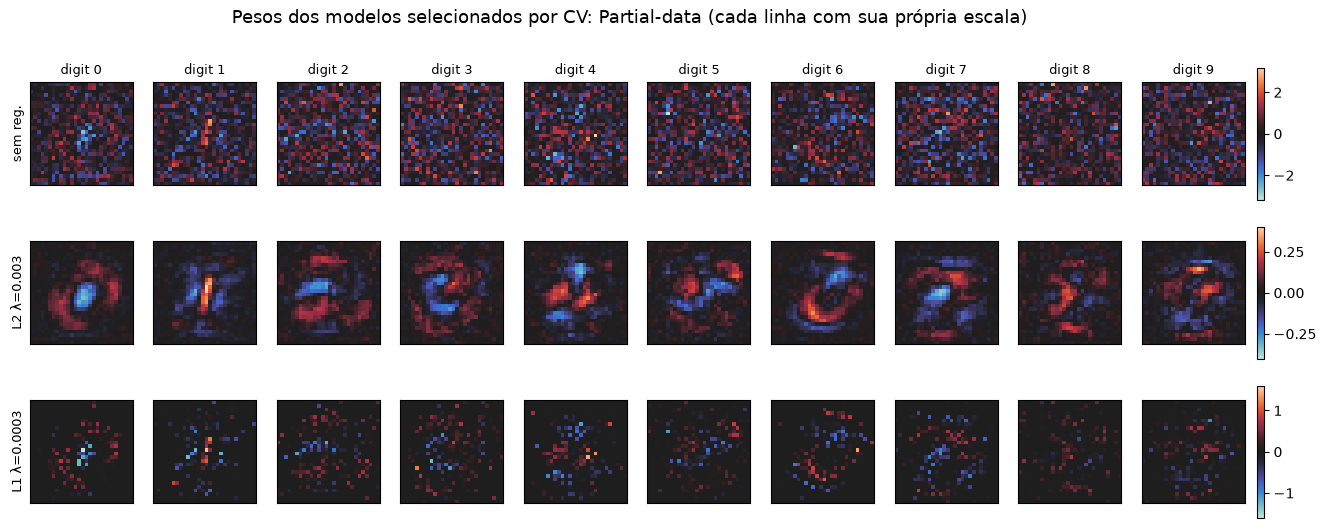

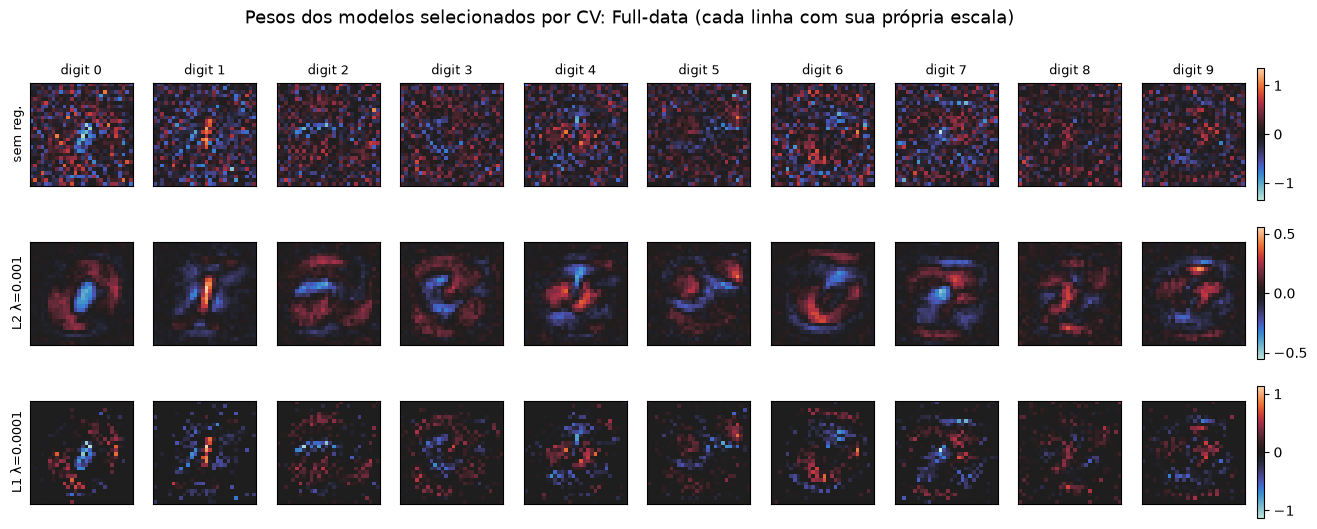

In [23]:
for name in regime_order:
    plot_weight_rows(
        {
            "sem reg.": final_models[name]["none"],
            f"L2 λ={selected[(name, 'L2')]:g}": final_models[name]["L2"],
            f"L1 λ={selected[(name, 'L1')]:g}": final_models[name]["L1"],
        },
        f"Pesos dos modelos selecionados por CV: {name}-data (cada linha com sua própria escala)",
    )

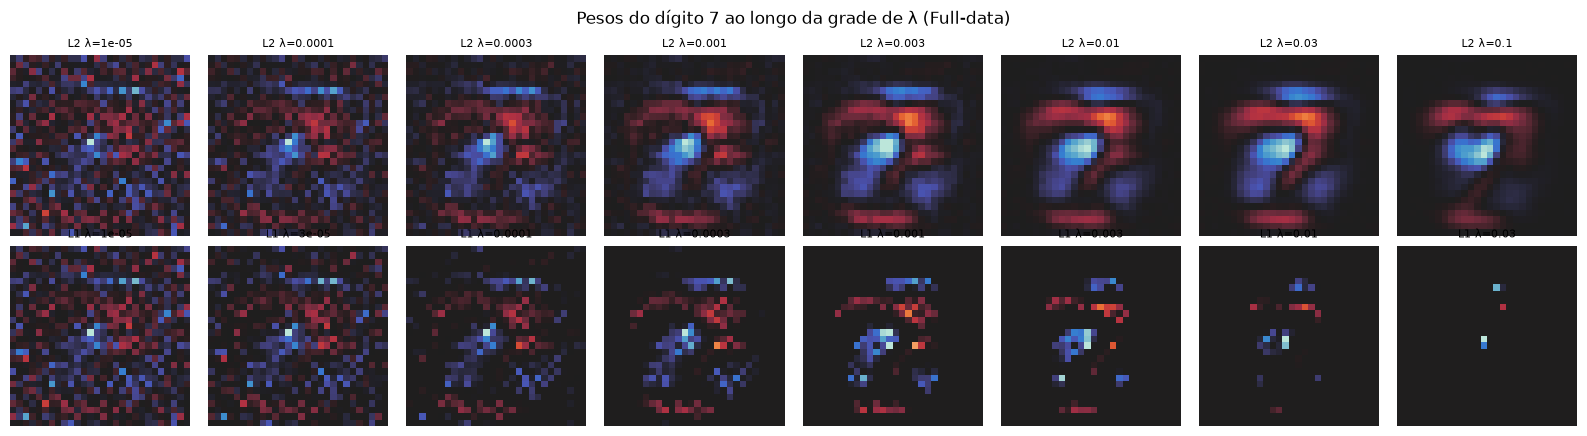

In [24]:
# Como os pesos evoluem ao longo da grade (Full-data), para um dígito fixo.
digit = 7
fig, axs = plt.subplots(2, 8, figsize=(16, 4.4))
for row, reg in enumerate(LAMBDAS):
    for col, lam in enumerate(LAMBDAS[reg]):
        w = full_grid_models[(reg, lam)].weights[digit].reshape(28, 28)
        vmax = np.abs(w).max() + 1e-12
        axs[row, col].imshow(w, cmap="icefire", vmin=-vmax, vmax=vmax)
        axs[row, col].set_title(f"{reg} λ={lam:g}", fontsize=8)
        axs[row, col].axis("off")
fig.suptitle(f"Pesos do dígito {digit} ao longo da grade de λ (Full-data)")
plt.tight_layout()
plt.show()

> **Question 3**
>
> (a) As $\lambda$ increases for L2 regularization, how does CV accuracy change on each data regime?
> Are there clear optima, or does accuracy plateau? Is the difference between the best $\lambda$ and its neighbours larger than the fold-to-fold standard deviation?
>
> (b) Compare the weight images of the CV-selected L2 model, the CV-selected L1 model, and the unregularized baseline. What differences do you observe in terms of structure and sparsity?
>
> (c) Connect the weight images to the corruption structure identified in Part 1. Does the CV-selected model appear to have suppressed the corruption pattern, amplified it, or is it ambiguous from weights alone?
>
> (d) **Predict**, based on what you see in the weights and CV curves, which of your three CV-selected models (none / L2 / L1) you expect will perform best on clean images, and which on images with impulse noise. Justify your prediction before seeing any test results.

**(a)** Para L2 (o L1 é análogo):

* **Scarce:** platô. Para $\lambda \le 3\times10^{-2}$ a CV fica entre 0,822 e 0,830, com desvio entre folds
  de 0,02-0,027, e cai para 0,545 em $\lambda = 0{,}1$. O melhor λ ($10^{-2}$, 0,830) supera os vizinhos por
  0,004 e 0,012, menos que o desvio entre folds (0,027) e menos que o desvio da diferença pareada (0,017 e
  0,014). Também não se distingue do baseline (0,825 ± 0,022). Com 200 imagens por fold de validação, a
  escolha de λ aqui é essencialmente ruído.
* **Partial:** há um ótimo claro. A CV sobe de 0,826 ($10^{-5}$) para **0,873 em $3\times10^{-3}$** e cai
  para 0,855 em $10^{-2}$, um ganho de +4,9 pontos sobre o baseline (0,824), o maior entre os regimes.
  - Vizinho da esquerda ($10^{-3}$): diferença de 0,0024, menor que o desvio entre folds (0,011). Porém, como
    os folds são os mesmos para todo λ, a diferença *pareada* tem desvio de só 0,0014; o melhor λ ganha de
    forma consistente, mas por pouco. É um platô entre $10^{-3}$ e $3\times10^{-3}$.
  - Vizinho da direita: diferença de 0,0175, bem acima do desvio.
* **Full:** sobe de 0,867 para **0,8837 em $10^{-3}$**, +1,9 ponto sobre o baseline (0,8645). O vizinho
  $3\times10^{-4}$ (0,8830) é indistinguível (diferença 0,0007 < desvio 0,0016); o vizinho $3\times10^{-3}$
  (0,8794) é claramente pior (diferença 0,0042, desvio pareado 0,0010).

O desvio entre folds cai de ~0,02 (Scarce) para ~0,01 (Partial) e ~0,002 (Full). Só com dados suficientes a CV
consegue separar os λ. Para o L1, os λ selecionados foram $3\times10^{-5}$ (Scarce, 0,822, *abaixo* do
baseline, logo nenhum λ de L1 ajuda), $3\times10^{-4}$ (Partial, 0,861) e $10^{-4}$ (Full, 0,881). L1 decai
mais rápido que L2 com λ e, nos três regimes, seu melhor valor fica abaixo do melhor L2.

**(b)**
* **Baseline:** sal e pimenta, moldes quase invisíveis (sobretudo no Partial), pesos grandes isolados na
  periferia.
* **L2:** moldes **suaves e contínuos**, como manchas que lembram os dígitos (0: centro negativo e anel
  positivo; 1: barra vertical; 7: barra superior e diagonal). A periferia fica escura, mas o modelo **não é
  esparso**: só 1,6% dos pesos têm $|w| < 10^{-3}$ no Full. Todos os pesos encolhem ($\|W\|_2$: 26,8 → 8,0;
  max $|w|$: 1,36 → 0,56).
* **L1:** **esparso** (62% de zeros no Full, 78% no Partial). Sobram pixels isolados ao longo dos traços,
  formando moldes "pontilhados", e os que sobram têm magnitudes maiores que no L2 (max $|w|$ 1,14). Nas
  células da grade (dígito 7), o L1 vai apagando o fundo até restarem só alguns pixels; o L2 vai borrando o
  molde até virar uma mancha.
* No Scarce, o λ do L1 escolhido é tão pequeno ($3\times10^{-5}$) que o modelo ainda parece o baseline.

**(c)** Na **periferia**, a resposta é clara: os modelos regularizados **suprimiram** a corrupção, que o
baseline tinha **amplificado**. A massa de $|W|$ na moldura cai de 13,8% (baseline Full) para 5,1% (L2) e
3,3% (L1); no Partial, de 12,2% para 5,8% e 3,1%. Na **região do dígito**, onde traços de corrupção e de
dígito se sobrepõem, é **ambíguo** só pelos pesos. Um peso só tem efeito multiplicado pela entrada, e os
traços da corrupção têm orientação aleatória, então não aparecem como um padrão reconhecível que poderíamos
procurar no molde. Os moldes do L2 contêm barras negativas que podem tanto codificar "ausência de tinta aqui
nesta classe" quanto penalizar traços espúrios.

**(d)** Previsão, feita antes de olhar o teste:
* **test_impulse:** o sal-e-pimenta acende pixels aleatórios em toda a imagem, exatamente os pixels raros em
  que o baseline pôs pesos grandes. Prevemos o **baseline como o pior**, por larga margem, e o **L2 como o
  melhor**: tem a menor norma, pesos espalhados e periferia controlada. O L1 deve ficar no meio: zera a
  periferia, mas concentra o peso em poucos pixels.
* **test_clean:** como a periferia é sempre zero nas imagens limpas, os pesos ruidosos do baseline deixam de
  atrapalhar. Esperamos diferenças pequenas, com o **L2 levemente à frente** por ter a melhor CV, e todos os
  modelos *melhores* no limpo do que no corrompido (sem os traços, só sobra o dígito).

---

## Part 4. Test

**(2.0 points)**

Until now, all decisions, dataset size analysis, regularization selection, were made using only the corrupted training data and cross-validation.
**Now we use the test sets** to evaluate the models you selected.

1. Evaluate all the chosen models (baseline, CV-selected L2 and L1, for each data regime) on the three test splits.
2. Using the Full-data models stored for every $\lambda$, plot the **trade-off curves**: accuracy on `test_corrupted` versus accuracy on `test_clean`, and versus `test_impulse`, one curve per regularizer, marking the CV-selected models.
3. Plot the **sparsity** (fraction of weights with $|w| < 10^{-3}$) of the L1 and L2 models against $\lambda$.
4. Compute the **per-class accuracy** on each test split for the CV-selected models and identify which digits suffer the most from each corruption.

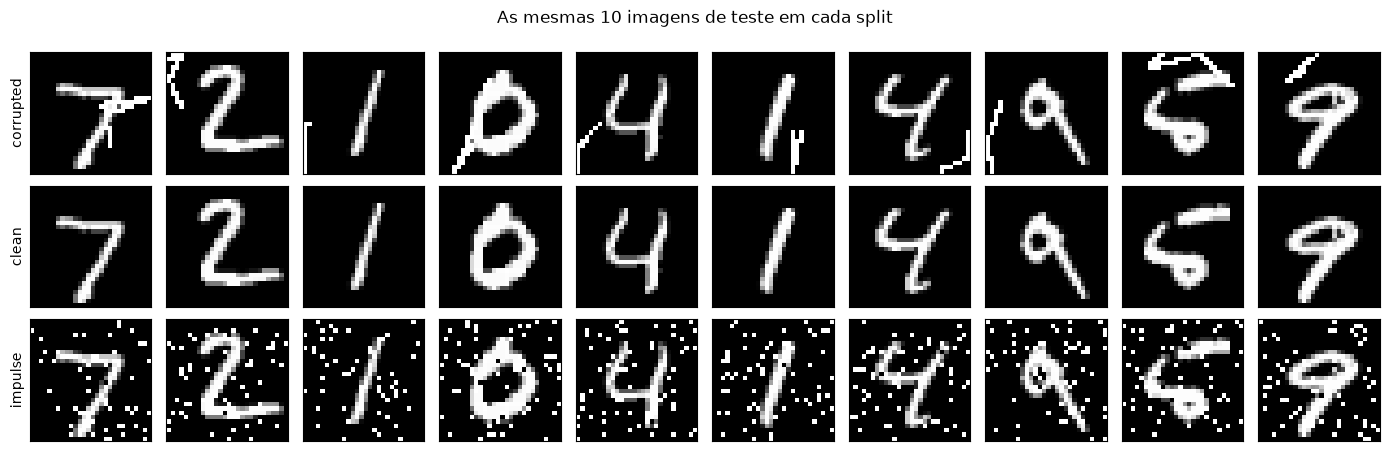

In [25]:
# Load the test datasets and evaluate all the chosen models for each data regime
y_test = np.load(f"{DATA_DIR}/test/test_labels.npy")
X_tests = {
    "corrupted": np.load(f"{DATA_DIR}/test/test_images.npy"),
    "clean": np.load(f"{DATA_DIR}/test/clean_images.npy"),
    "impulse": np.load(f"{DATA_DIR}/test/impulse_images.npy"),
}
splits = list(X_tests)
y_test_t = torch.from_numpy(y_test)

# Mesmas imagens nos três splits
fig, axs = plt.subplots(3, 10, figsize=(14, 4.6))
for row, split in enumerate(splits):
    for col in range(10):
        axs[row, col].imshow(X_tests[split][col, ..., 0], cmap="gray", vmin=0, vmax=255)
        axs[row, col].set_xticks([]); axs[row, col].set_yticks([])
    axs[row, 0].set_ylabel(split, fontsize=10)
fig.suptitle("As mesmas 10 imagens de teste em cada split")
plt.tight_layout()
plt.show()

# Teste transformado com o pré-processador AJUSTADO NO TREINO de cada regime (sem reajuste)
test_tensors = {
    name: {split: preprocessors[name].transform(X) for split, X in X_tests.items()}
    for name in regime_order
}


def evaluate(model: LinearModel, regime: str) -> dict[str, float]:
    return {split: accuracy(predict_logits(model, test_tensors[regime][split]), y_test_t) for split in splits}

,regime,model,λ,CV,corrupted,clean,impulse,gap clean,gap impulse
0,Scarce,none,0,0.8250 ± 0.0215,0.8393,0.8673,0.8239,-0.0280,0.0154
1,Scarce,L2,0.01,0.8300 ± 0.0274,0.8532,0.8668,0.8522,-0.0136,0.0010
2,Scarce,L1,3e-05,0.8220 ± 0.0175,0.8395,0.8661,0.8201,-0.0266,0.0194
3,Partial,none,0,0.8243 ± 0.0062,0.8264,0.8861,0.6751,-0.0597,0.1513
4,Partial,L2,0.003,0.8728 ± 0.0106,0.8821,0.8958,0.8805,-0.0137,0.0016
5,Partial,L1,0.0003,0.8614 ± 0.0118,0.8690,0.9010,0.8434,-0.0320,0.0256
6,Full,none,0,0.8645 ± 0.0014,0.8762,0.9047,0.7464,-0.0285,0.1298
7,Full,L2,0.001,0.8837 ± 0.0016,0.8920,0.9041,0.8836,-0.0121,0.0084
8,Full,L1,0.0001,0.8812 ± 0.0023,0.8903,0.9058,0.8718,-0.0155,0.0185


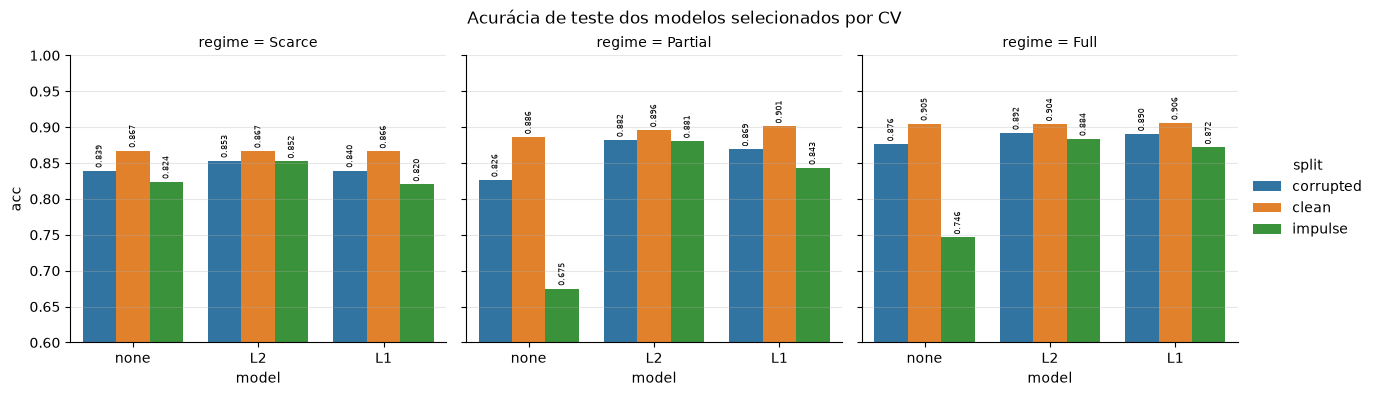

In [26]:
eval_rows = []
for name in regime_order:
    for kind, model in final_models[name].items():
        lam = selected.get((name, kind), 0.0)
        cv_row = cv_df[(cv_df.regime == name) & (cv_df.reg == kind) & np.isclose(cv_df.lam, lam)].iloc[0]
        accs = evaluate(model, name)
        eval_rows.append({"regime": name, "model": kind, "λ": f"{lam:g}",
                          "CV": f"{cv_row.cv_mean:.4f} ± {cv_row.cv_std:.4f}", **accs,
                          "gap clean": accs["corrupted"] - accs["clean"],
                          "gap impulse": accs["corrupted"] - accs["impulse"]})
eval_df = pd.DataFrame(eval_rows)
display(eval_df.round(4))

plot_df = eval_df.melt(id_vars=["regime", "model"], value_vars=splits, var_name="split", value_name="acc")
g = sns.catplot(data=plot_df, x="model", y="acc", hue="split", col="regime", col_order=regime_order,
                kind="bar", height=3.8, aspect=1.1)
for ax in g.axes.flat:
    ax.set_ylim(np.floor(plot_df.acc.min() * 20) / 20 - 0.05, 1.0)
    ax.grid(axis="y", alpha=0.3)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=6, rotation=90, padding=2)
g.figure.suptitle("Acurácia de teste dos modelos selecionados por CV", y=1.03)
plt.show()

**Regularização implícita do otimizador.** Todos os modelos usam FISTA, que leva o objetivo perto do ótimo
em 500 iterações. Para medir quanto o *otimizador* regulariza por conta própria, treinamos o mesmo baseline
(λ = 0, 500 iterações, mesmo lr) com gradiente descendente simples, que para bem antes do ótimo (early stopping).

In [27]:
opt_rows = []
for name in regime_order:
    Xt, yt = train_tensors[name]
    gd_model, gd_losses = fit_model(Xt, yt, accelerated=False)
    for label, model, losses in [("FISTA (usado no notebook)", final_models[name]["none"], baseline_losses[name]),
                                 ("GD simples (early stopping)", gd_model, gd_losses)]:
        opt_rows.append({"regime": name, "otimizador": label, "perda final": losses[-1],
                         "||W||_2": float(np.linalg.norm(model.weights)),
                         "treino": accuracy(predict_logits(model, Xt), yt), **evaluate(model, name)})
pd.DataFrame(opt_rows).round(4)

,regime,otimizador,perda final,||W||_2,treino,corrupted,clean,impulse
0,Scarce,FISTA (usado no notebook),0.0004,27.5538,1.0000,0.8393,0.8673,0.8239
1,Scarce,GD simples (early stopping),0.0482,11.3578,1.0000,0.8497,0.8735,0.8405
2,Partial,FISTA (usado no notebook),0.0337,64.8049,0.9991,0.8264,0.8861,0.6751
3,Partial,GD simples (early stopping),0.3009,9.5647,0.9156,0.8817,0.9037,0.8793
4,Full,FISTA (usado no notebook),0.3103,26.7723,0.9078,0.8762,0.9047,0.7464
5,Full,GD simples (early stopping),0.3724,8.6419,0.8905,0.8918,0.9097,0.8880


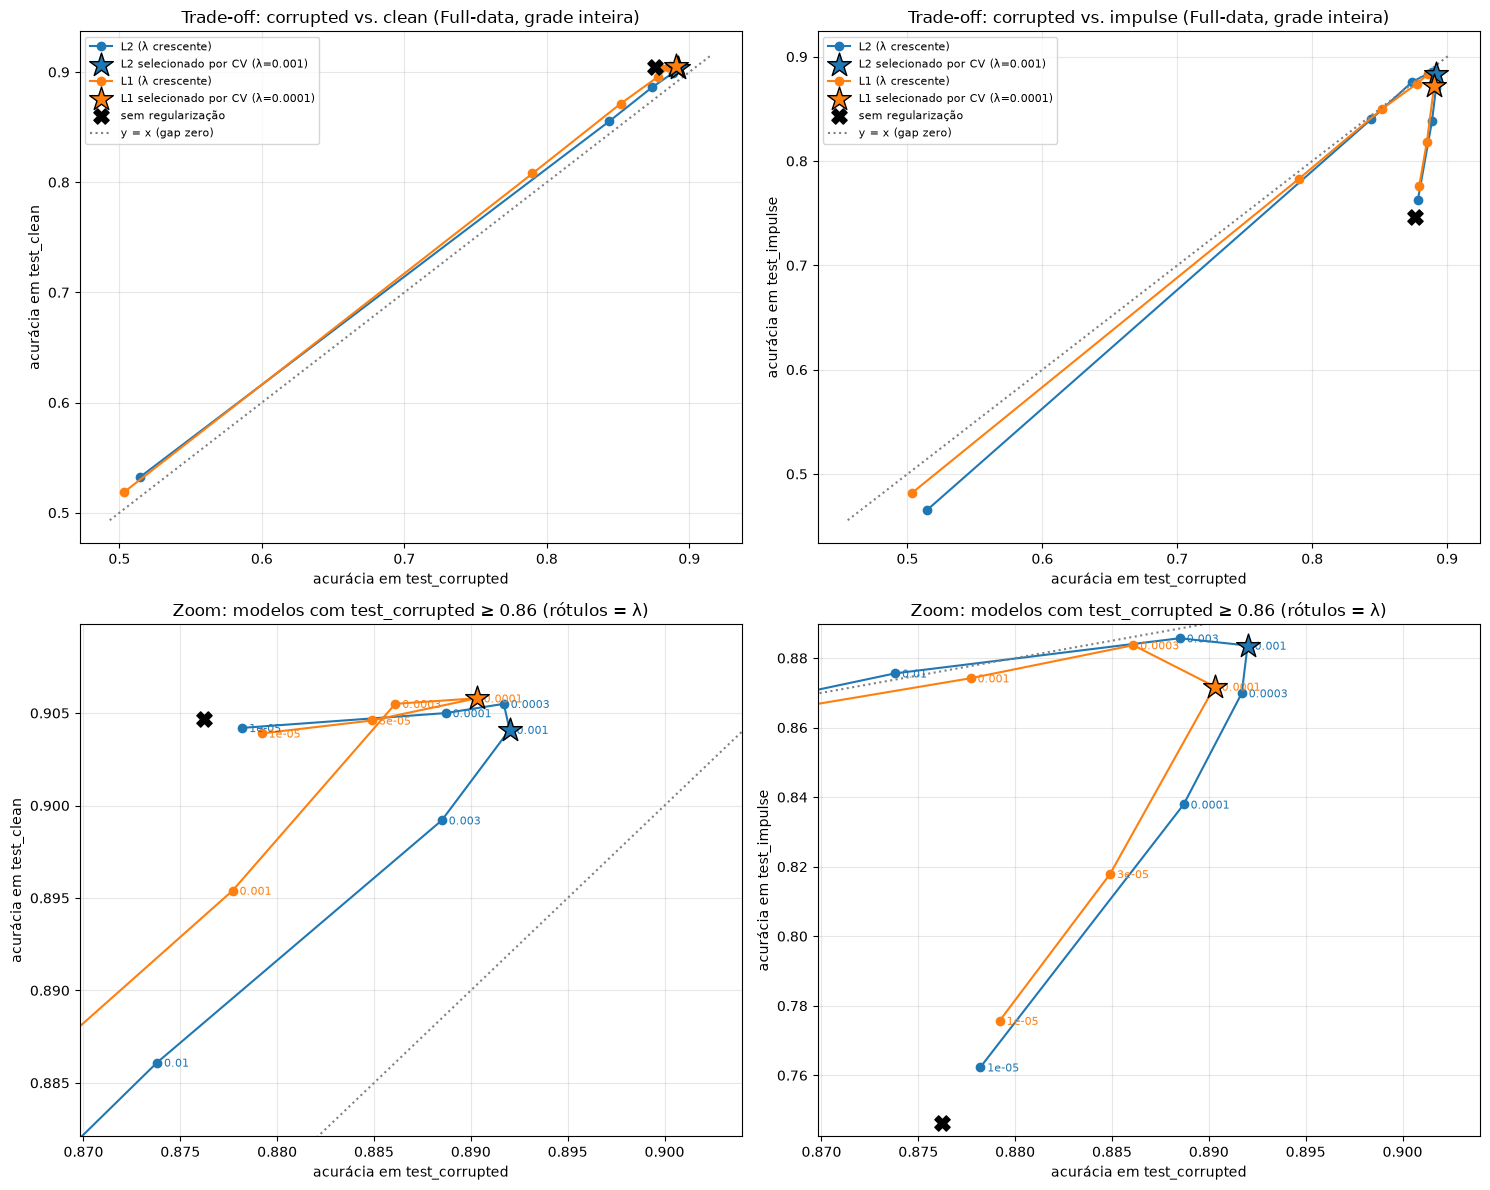

In [28]:
# Todos os modelos da grade (Full-data) nos três splits
grid_rows = []
for (reg, lam), model in full_grid_models.items():
    cv_row = cv_df[(cv_df.regime == "Full") & (cv_df.reg == reg) & np.isclose(cv_df.lam, lam)].iloc[0]
    grid_rows.append({"reg": reg, "lam": lam, "cv_mean": cv_row.cv_mean, "cv_std": cv_row.cv_std,
                      **evaluate(model, "Full"), "sparsity": sparsity(model),
                      "frame_share": frame_weight_share(model)})
grid_df = pd.DataFrame(grid_rows)
grid_df["gap_clean"] = grid_df.corrupted - grid_df.clean
grid_df["gap_impulse"] = grid_df.corrupted - grid_df.impulse

base = grid_df[grid_df.reg == "none"].iloc[0]
# Região de zoom: modelos com acurácia em test_corrupted >= 0.86 (onde ficam os bons modelos)
zoom = grid_df[grid_df.corrupted >= 0.86]


def draw_tradeoff(ax: plt.Axes, target: str, annotate: bool) -> None:
    for reg in LAMBDAS:
        r = grid_df[grid_df.reg == reg].sort_values("lam")
        ax.plot(r.corrupted, r[target], marker="o", color=colors[reg], label=f"{reg} (λ crescente)")
        if annotate:
            for _, row in r[r.corrupted >= 0.86].iterrows():
                ax.annotate(f"{row.lam:g}", (row.corrupted, row[target]), fontsize=8,
                            textcoords="offset points", xytext=(5, -3), color=colors[reg])
        sel = r[np.isclose(r.lam, selected[("Full", reg)])].iloc[0]
        ax.scatter(sel.corrupted, sel[target], s=320, marker="*", color=colors[reg], edgecolor="k",
                   zorder=5, label=f"{reg} selecionado por CV (λ={sel.lam:g})")
    ax.scatter(base.corrupted, base[target], s=120, marker="X", color="k", zorder=5, label="sem regularização")
    lims = [min(grid_df.corrupted.min(), grid_df[target].min()) - 0.01,
            max(grid_df.corrupted.max(), grid_df[target].max()) + 0.01]
    ax.plot(lims, lims, ls=":", color="gray", label="y = x (gap zero)")
    ax.set_xlabel("acurácia em test_corrupted")
    ax.set_ylabel(f"acurácia em test_{target}")
    ax.grid(alpha=0.3)


fig, axs = plt.subplots(2, 2, figsize=(15, 12))
for col, target in enumerate(["clean", "impulse"]):
    draw_tradeoff(axs[0, col], target, annotate=False)
    axs[0, col].set_title(f"Trade-off: corrupted vs. {target} (Full-data, grade inteira)")
    axs[0, col].legend(fontsize=8)
    draw_tradeoff(axs[1, col], target, annotate=True)
    pad = 0.004
    axs[1, col].set_xlim(zoom.corrupted.min() - pad, zoom.corrupted.max() + 3 * pad)
    axs[1, col].set_ylim(zoom[target].min() - pad, zoom[target].max() + pad)
    axs[1, col].set_title(f"Zoom: modelos com test_corrupted ≥ 0.86 (rótulos = λ)")
plt.tight_layout()
plt.show()

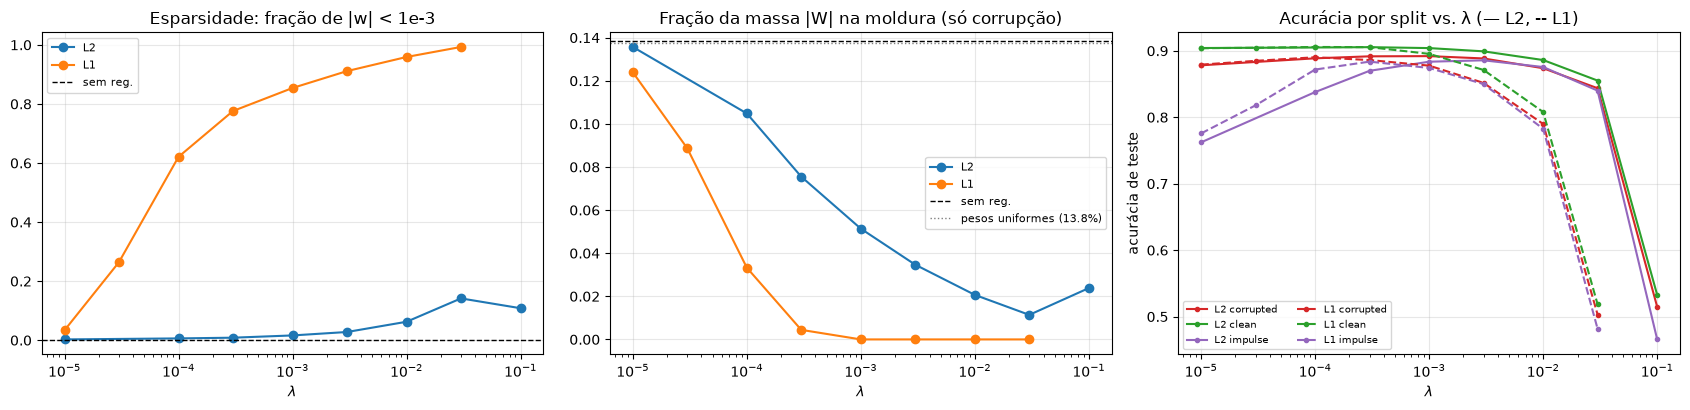

,reg,lam,cv_mean,cv_std,corrupted,clean,impulse,sparsity,frame_share,gap_clean,gap_impulse
0,none,0,0.8645,0.0014,0.8762,0.9047,0.7464,0.0020,0.1384,-0.0285,0.1298
1,L2,1e-05,0.8673,0.0014,0.8782,0.9042,0.7623,0.0027,0.1357,-0.0260,0.1159
2,L2,0.0001,0.8791,0.0021,0.8887,0.9050,0.8379,0.0061,0.1048,-0.0163,0.0508
3,L2,0.0003,0.8830,0.0020,0.8917,0.9055,0.8699,0.0085,0.0755,-0.0138,0.0218
4,L2,0.001,0.8837,0.0016,0.8920,0.9041,0.8836,0.0162,0.0514,-0.0121,0.0084
5,L2,0.003,0.8794,0.0025,0.8885,0.8992,0.8857,0.0278,0.0347,-0.0107,0.0028
6,L2,0.01,0.8639,0.0049,0.8738,0.8861,0.8756,0.0625,0.0207,-0.0123,-0.0018
7,L2,0.03,0.8307,0.0046,0.8437,0.8552,0.8401,0.1416,0.0114,-0.0115,0.0036
8,L2,0.1,0.4755,0.0774,0.5147,0.5326,0.4657,0.1083,0.0238,-0.0179,0.0490
9,L1,1e-05,0.8691,0.0018,0.8792,0.9039,0.7757,0.0337,0.1239,-0.0247,0.1035


In [29]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.2))
for reg in LAMBDAS:
    r = grid_df[grid_df.reg == reg].sort_values("lam")
    axs[0].plot(r.lam, r.sparsity, marker="o", color=colors[reg], label=reg)
    axs[1].plot(r.lam, r.frame_share, marker="o", color=colors[reg], label=reg)
axs[0].axhline(base.sparsity, color="k", ls="--", lw=1, label="sem reg.")
axs[1].axhline(base.frame_share, color="k", ls="--", lw=1, label="sem reg.")
axs[1].axhline(108 / 784, color="gray", ls=":", lw=1, label="pesos uniformes (13.8%)")
axs[0].set_title("Esparsidade: fração de |w| < 1e-3")
axs[1].set_title("Fração da massa |W| na moldura (só corrupção)")
for ax in axs[:2]:
    ax.set_xscale("log"); ax.set_xlabel(r"$\lambda$"); ax.grid(alpha=0.3); ax.legend(fontsize=8)

for reg, ls in [("L2", "-"), ("L1", "--")]:
    r = grid_df[grid_df.reg == reg].sort_values("lam")
    for split, c in zip(splits, ["tab:red", "tab:green", "tab:purple"]):
        axs[2].plot(r.lam, r[split], ls=ls, marker="o", ms=3, color=c, label=f"{reg} {split}")
axs[2].set_xscale("log"); axs[2].set_xlabel(r"$\lambda$"); axs[2].set_ylabel("acurácia de teste")
axs[2].set_title("Acurácia por split vs. λ (— L2, -- L1)")
axs[2].grid(alpha=0.3); axs[2].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

grid_df.assign(lam=grid_df.lam.map("{:g}".format)).round(4)

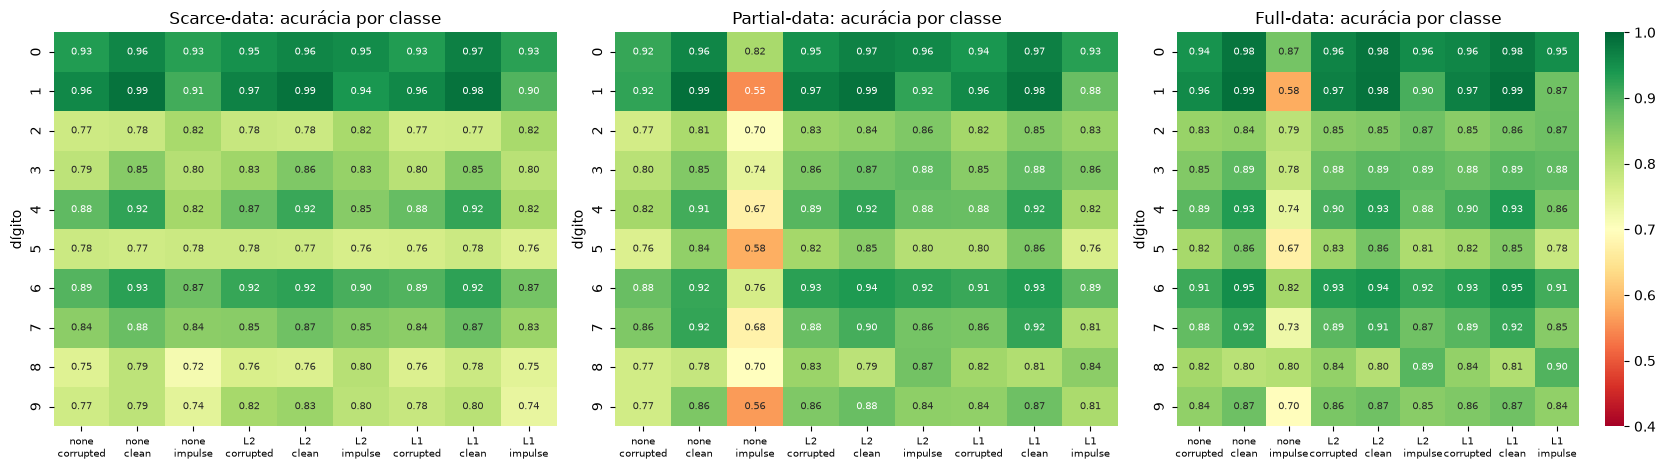

,corrupted → clean,corrupted → impulse,acc corrupted (média)
0,-0.026,0.023,0.943
1,-0.028,0.132,0.958
2,-0.013,-0.012,0.807
3,-0.034,0.006,0.836
4,-0.043,0.064,0.880
5,-0.032,0.052,0.796
6,-0.023,0.037,0.911
7,-0.035,0.053,0.866
8,0.008,-0.009,0.798
9,-0.028,0.057,0.821


In [30]:
def per_class_accuracy(model: LinearModel, regime: str, split: str) -> NDArray[np.float64]:
    y_pred = predict_logits(model, test_tensors[regime][split]).argmax(dim=-1).numpy()
    return np.array([(y_pred[y_test == d] == d).mean() for d in range(10)])


fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))
per_class = {}
for ax, name in zip(axs, regime_order):
    table = pd.DataFrame({
        (kind, split): per_class_accuracy(model, name, split)
        for kind, model in final_models[name].items() for split in splits
    })
    per_class[name] = table
    sns.heatmap(table, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0.4, vmax=1.0, ax=ax,
                cbar=ax is axs[-1], annot_kws={"fontsize": 7})
    ax.set_xticklabels([f"{k}\n{s}" for k, s in table.columns], fontsize=7, rotation=0)
    ax.set_xlabel("")
    ax.set_ylabel("dígito")
    ax.set_title(f"{name}-data: acurácia por classe")
plt.tight_layout()
plt.show()

# Queda de acurácia por classe em relação ao test_corrupted (média entre os modelos e regimes)
drops = pd.DataFrame({
    f"corrupted → {split}": np.mean([per_class[n][(k, "corrupted")] - per_class[n][(k, split)]
                                    for n in regime_order for k in final_models[n]], axis=0)
    for split in ["clean", "impulse"]
})
drops["acc corrupted (média)"] = np.mean([per_class[n][(k, "corrupted")] for n in regime_order for k in final_models[n]], axis=0)
drops.round(3)

In [31]:
# Principais confusões (verdadeiro -> previsto) de cada split, para o modelo L2 selecionado no Full-data
model = final_models["Full"]["L2"]
top_confusions = {}
for split in splits:
    y_pred = predict_logits(model, test_tensors["Full"][split]).argmax(dim=-1).numpy()
    cm = pd.crosstab(pd.Series(y_test, name="true"), pd.Series(y_pred, name="pred"))
    errors = cm.stack().reset_index(name="n").query("true != pred").nlargest(8, "n")
    top_confusions[split] = [f"{t} → {p} ({n})" for t, p, n in errors.itertuples(index=False)]
pd.DataFrame(top_confusions)

,corrupted,clean,impulse
0,4 → 9 (56),9 → 4 (50),1 → 8 (76)
1,9 → 4 (50),8 → 5 (40),5 → 8 (59)
2,7 → 9 (49),4 → 9 (38),5 → 3 (57)
3,2 → 8 (47),8 → 1 (36),2 → 8 (53)
4,5 → 3 (45),3 → 5 (33),9 → 4 (53)
5,8 → 3 (36),7 → 9 (32),4 → 9 (52)
6,3 → 5 (35),2 → 8 (31),7 → 9 (44)
7,8 → 5 (32),9 → 7 (31),3 → 8 (43)


> **Question 4**
>
> (a) Describe the shape of the trade-off curve (corrupted-test vs. clean-test). Is there a region where increasing regularization simultaneously improves both accuracies? Is there a region of genuine trade-off?
>
> (b) The CV-selected models are marked on the plot. Where do they fall relative to the trade-off frontier? What does this tell you about using cross-validation as a model selection criterion when training and deployment distributions differ?
>
> (c) Revisit your prediction from Question 3(d). Was it correct? If not, what did the weight images fail to reveal that the test results exposed?
>
> (d) Connect the sparsity plot to the out-of-distribution results. Why might L1 regularization behave differently from L2 when evaluated on clean images and on impulse noise?
>
> (e) Compare `test_clean` and `test_impulse`. Did training on one corruption make the model robust to a different one? Which data regime and which regularizer transferred best, and why?
>
> (f) Use the per-class accuracies to check your answer to Question 1.1(c). Which digits suffer the most under each corruption?
>
> (g) In a real deployment scenario, neither the clean nor the impulse test set would be available during model selection. Given only corrupted validation data, what practical strategies could a practitioner use to make a better model selection decision than simply maximizing CV accuracy?

*(Erro padrão de uma acurácia em 10 000 imagens ≈ 0,003; como os três splits têm as mesmas imagens, as
comparações entre modelos são pareadas e um pouco mais precisas que isso.)*

**(a)** **Corrupted × clean:** a curva é quase uma reta paralela a $y = x$, um pouco acima dela (o limpo é
sempre ~1-2 pontos mais fácil).
* De λ = 0 até $3\times10^{-4}$ (L2), a acurácia no corrompido sobe de 0,876 para 0,892 enquanto a do limpo
  fica parada (0,9047 → 0,9055): uma pequena região de melhora conjunta, quase toda no eixo corrompido.
* A partir daí, as duas caem juntas. A única "troca" (entre $3\times10^{-4}$ e $10^{-3}$: +0,0003 no
  corrompido, −0,0014 no limpo) está dentro do ruído.
* Não há trade-off genuíno: a acurácia no limpo é praticamente função monótona da acurácia no corrompido.

**Corrupted × impulse:** a história é diferente.
* Há uma região longa de **melhora simultânea**: de λ = 0 a $10^{-3}$ (L2), o corrompido sobe 1,6 ponto e o
  impulse sobe **13,7 pontos** (0,746 → 0,884).
* Depois há um trecho curto de **trade-off genuíno**:
  - L2, de $10^{-3}$ para $3\times10^{-3}$: −0,35 ponto no corrompido, +0,2 no impulse;
  - L1, de $10^{-4}$ para $3\times10^{-4}$: −0,4 no corrompido, **+1,2** no impulse.
* Além disso, ambos caem.

**(b)**
* **Corrupted × clean:** os modelos selecionados por CV estão **na fronteira**, no topo da curva (máximo do
  corrompido e limpo a ≤ 0,002 do máximo).
* **Corrupted × impulse:** o L2 ($10^{-3}$) está no "joelho", a 0,2 ponto do melhor impulse da grade
  ($3\times10^{-3}$). O L1 ($10^{-4}$) fica **antes** do joelho: $3\times10^{-4}$ teria dado +1,2 ponto no
  impulse por −0,4 no corrompido.

O padrão é que a CV escolhe o λ ótimo *para a distribuição de treino*, e a robustez a deslocamentos tende a
pedir um λ um pouco **maior**. Aqui a CV funcionou razoavelmente porque o deslocamento para o impulse pune o
mesmo defeito que o overfitting pune dentro da distribuição: pesos grandes em pixels raramente acesos. Até o
ótimo da CV, os dois critérios andam juntos. Isso é sorte do par de corrupções, não garantia: a CV é cega à
direção do deslocamento, e com um deslocamento diferente nada garante esse alinhamento. No Scarce, onde as
diferenças de CV são menores que o ruído, a seleção é quase aleatória. Por exemplo, o L1 escolhido
($3\times10^{-5}$) tem 0,820 no impulse, contra 0,852 do L2.

**(c)**

| | Scarce | Partial | Full |
|---|---|---|---|
| Ordem no **impulse** | L2 0,852 > none 0,824 ≈ L1 0,820 | L2 0,881 > L1 0,843 > none 0,675 | L2 0,884 > L1 0,872 > none 0,746 |
| **clean** (none / L2 / L1) | 0,867 / 0,867 / 0,866 | 0,886 / 0,896 / **0,901** | 0,905 / 0,904 / **0,906** |

* **Impulse:** a previsão estava certa em Partial e Full. O L2 é o melhor e o baseline o pior; só no Scarce o
  L1 empata com o baseline.
* **Clean:** a previsão estava **errada** em um ponto. O L2 não foi o melhor: no Full os três empatam dentro do
  ruído, e no Partial o **L1** é o melhor.

O que os pesos não mostravam é **com que entrada eles seriam multiplicados**. O baseline tem pesos
"feios", mas nas imagens limpas a periferia é zero e esses pesos simplesmente não são usados: o dano é
latente e só aparece quando o teste acende os pixels raros (impulse, −13 pontos). Do mesmo modo, os moldes
pontilhados do L1 parecem frágeis, mas acertam bem dígitos limpos, que têm exatamente os traços que eles
guardaram. Os pesos indicavam a *direção* dos efeitos, mas não sua *magnitude* nem *em qual distribuição*
eles se manifestariam.

**(d)** **Esparsidade:**
* **L1:** a fração de pesos com $|w|<10^{-3}$ sobe rápido: 62% ($10^{-4}$), 78% ($3\times10^{-4}$), 85%
  ($10^{-3}$), 99% ($3\times10^{-2}$).
* **L2:** fica abaixo de 6% até $\lambda = 10^{-2}$; encolhe, mas não zera.
* **Moldura:** o L1 zera *exatamente* os pesos da moldura a partir de $\lambda = 10^{-3}$, enquanto o L2 só os
  reduz aos poucos.

**No limpo:** zerar pesos de pixels que são zero nas imagens limpas não custa nada, e o L1 mantém os pixels
mais discriminativos com pesos fortes. Daí o L1 ir bem no limpo.

**No impulse:** pense no efeito do ruído no logit, $\Delta z_k = \sum_j w_{kj}\,\varepsilon_j$. Para ruído
independente por pixel com variância $\sigma^2$, a variância desse termo é $\sigma^2 \sum_j w_{kj}^2$. Essa é
*exatamente* a penalidade L2: o **L2 minimiza diretamente a sensibilidade a ruído i.i.d. por pixel**,
espalhando o peso por muitos pixels correlacionados, de modo que o ruído se cancela. O L1 zera a periferia,
o que ajuda, mas concentra o peso em poucos pixels centrais com magnitude grande. Um único pixel de sal (ou
pimenta) que caia num desses pixels-chave muda muito o logit, e para a mesma norma L1, pesos concentrados
têm norma L2 maior. A ordem de $\|W\|_2$ dos modelos selecionados acompanha a ordem do impulse:

| | none | L1 | L2 |
|---|---|---|---|
| Full: $\|W\|_2$ | 26,8 | 13,0 | 8,0 |
| Full: impulse | 0,746 | 0,872 | 0,884 |
| Partial: $\|W\|_2$ | 64,8 | 14,9 | 6,5 |
| Partial: impulse | 0,675 | 0,843 | 0,881 |

**(e)** Treinar com zigzag **não** tornou os modelos robustos ao impulse por si só: o baseline Full perde 13
pontos e o Partial perde 15 (0,826 → 0,675). O que transferiu não foi "robustez a traços", e sim a
**insensibilidade a pixels espúrios acesos** que a regularização induz. Com L2, o gap do impulse cai para
0,1-0,8 ponto em todos os regimes. Para o limpo, todos os modelos *melhoram* (gap negativo): o modelo trata
os traços como ruído, então removê-los só ajuda. O maior ganho é o do baseline Partial (+6 pontos), o
modelo mais prejudicado pelos traços.

A melhor transferência foi do **L2**: melhor impulse absoluto no **Full** (0,884) e menores gaps no Scarce
(0,001) e no Partial (0,002). Isso por dois motivos:
1. pela razão do item (d);
2. porque mais dados reduzem a variância dos pesos de pixels raros.

O experimento com GD simples reforça o ponto. O mesmo baseline, parado cedo, tem 0,888 no impulse no Full e
0,879 no Partial: o early stopping também limita $\|W\|$ (8,6 e 9,6 em vez de 26,8 e 64,8) e funciona como
regularização implícita. Não temos um modelo treinado em dados limpos para comparar, então não dá para dizer
se o zigzag ajudou ou atrapalhou em relação a não ter corrupção nenhuma.

**(f)** Média por dígito entre todos os modelos selecionados:

* **Zigzag** (comparação corrupted × clean): os dígitos que mais ganham quando os traços são removidos são o
  **4** (+4,3 pontos), o **7** (+3,5), o 3 (+3,4) e o 5 (+3,2). As confusões mais frequentes no corrompido
  são 4→9, 9→4, 7→9, 2→8 e 5→3: um traço extra fecha o topo do 4 (vira 9), completa o laço do 7 ou do 2.
  - Acertamos o 4 e o 7 e a direção "para o dígito com mais tinta".
  - **Erramos sobre o 1**: ele continua o dígito mais fácil (0,958 no corrompido) e perde só 2,8 pontos.
    O molde do 1 depende de uma coluna estreita no centro, que um traço aleatório raramente atravessa por
    inteiro.
  - O **8** é até ligeiramente *melhor* no corrompido (+0,8): tinta extra empurra para a classe "cheia".
  - Os dígitos com menor acurácia no corrompido são 5 (0,80), 8 (0,80), 2 e 9 (0,82).
* **Impulse:** o mais prejudicado de longe é o **1** (−13,2 pontos em média; 0,55-0,58 nos baselines
  Partial e Full), seguido de 4 (−6,4), 9 (−5,7), 7 (−5,3) e 5 (−5,2). As confusões dominantes vão para o 8:
  1→8 (76 casos mesmo no L2 Full), 5→8 e 2→8. O 2 e o 8 até melhoram. O sal adiciona tinta em toda a
  imagem, e o dígito com menos tinta própria (o 1) é o primeiro a ser "afogado", migrando para a classe mais
  densa. Aqui a nossa intuição sobre o 1 valeu, mas para a corrupção errada.

**(g)** Estratégias para escolher melhor só com dados corrompidos:

1. **Regra de um desvio padrão:** entre os λ cuja CV está a até um erro padrão do melhor, escolher o *mais
   regularizado*. Aqui, para L1 no Full, $3\times10^{-4}$ (0,8803) fica no limite do critério do melhor λ
   (0,8812 ± 0,0010 de erro padrão). Isso daria +1,2 ponto no impulse sem perda no limpo. Desempatar para o
   lado mais simples é barato e costuma ser mais robusto.
2. **Testes de estresse sintéticos:** aplicar aos folds de validação uma *família* de perturbações plausíveis
   (ruído impulsivo, gaussiano, blur, oclusões, outras corrupções do MNIST-C) e escolher λ pela acurácia
   média ou pior caso, tomando cuidado para não ajustar exatamente a corrupção do teste.
3. **Métricas de sensibilidade que não precisam de rótulos de outra distribuição:**
   - $\|W\|_2$ (a sensibilidade a ruído, como no item d);
   - a estabilidade das predições sob perturbações aleatórias;
   - a massa de peso em regiões sabidamente não informativas, como a nossa moldura. Isso é conhecimento de
     domínio: dígitos não chegam na borda.
4. **Data augmentation e priors estruturais:** treinar com ruído/traços aleatórios adicionais e preferir
   pesos suaves (L2, variação total). Isso torna o modelo invariante ao que sabemos ser irrelevante, em vez
   de torcer para a CV descobrir.
5. **Usar dados não rotulados da implantação**, se existirem, para detectar o deslocamento (comparar
   histogramas de pixels, entropia das predições) e reponderar ou revalidar. Ensembles de vários λ também
   reduzem a dependência de uma escolha pontual.

In [32]:
# Linhas da tabela-resumo (Full-data). "Smallest gap" = menor valor do gap com sinal
# (menor degradação de corrupted para o outro split), escolhido entre os modelos da grade.
def summary_row(label: str, row: pd.Series) -> dict[str, Any]:
    return {"Model": label, "λ": f"{row.lam:g}", "CV (mean ± std)": f"{row.cv_mean:.4f} ± {row.cv_std:.4f}",
            "corrupted": row.corrupted, "clean": row.clean, "impulse": row.impulse,
            "Gap clean": row.gap_clean, "Gap impulse": row.gap_impulse}


def pick(reg: str, lam: float) -> pd.Series:
    return grid_df[(grid_df.reg == reg) & np.isclose(grid_df.lam, lam)].iloc[0]


summary = [summary_row("No regularization (baseline)", pick("none", 0.0))]
for reg in ["L2", "L1"]:
    summary.append(summary_row(f"Best CV, {reg}", pick(reg, selected[("Full", reg)])))
for gap in ["clean", "impulse"]:
    for reg in ["L2", "L1"]:
        r = grid_df[grid_df.reg == reg]
        summary.append(summary_row(f"Smallest {gap} gap, {reg}", r.loc[r[f"gap_{gap}"].idxmin()]))
summary_df = pd.DataFrame(summary)
summary_df.round(4)

,Model,λ,CV (mean ± std),corrupted,clean,impulse,Gap clean,Gap impulse
0,No regularization (baseline),0,0.8645 ± 0.0014,0.8762,0.9047,0.7464,-0.0285,0.1298
1,"Best CV, L2",0.001,0.8837 ± 0.0016,0.8920,0.9041,0.8836,-0.0121,0.0084
2,"Best CV, L1",0.0001,0.8812 ± 0.0023,0.8903,0.9058,0.8718,-0.0155,0.0185
3,"Smallest clean gap, L2",1e-05,0.8673 ± 0.0014,0.8782,0.9042,0.7623,-0.0260,0.1159
4,"Smallest clean gap, L1",1e-05,0.8691 ± 0.0018,0.8792,0.9039,0.7757,-0.0247,0.1035
5,"Smallest impulse gap, L2",0.01,0.8639 ± 0.0049,0.8738,0.8861,0.8756,-0.0123,-0.0018
6,"Smallest impulse gap, L1",0.003,0.8440 ± 0.0015,0.8517,0.8712,0.8499,-0.0195,0.0018


---

## Summary

Complete the table below with results from your experiments (Full-data regime). Use the best model according to each criterion.

| Model                              | $\lambda$ | CV Accuracy (mean ± std) | Test Acc (corrupted) | Test Acc (clean) | Test Acc (impulse) | Gap clean | Gap impulse |
|------------------------------------|-----------|--------------------------|----------------------|------------------|--------------------|-----------|-------------|
| No regularization (baseline)       | 0         | 0.8645 ± 0.0014          | 0.8762               | 0.9047           | 0.7464             | −0.0285   | 0.1298      |
| Best CV, L2                        | 1e-3      | 0.8837 ± 0.0016          | 0.8920               | 0.9041           | 0.8836             | −0.0121   | 0.0084      |
| Best CV, L1                        | 1e-4      | 0.8812 ± 0.0023          | 0.8903               | 0.9058           | 0.8718             | −0.0155   | 0.0185      |
| Smallest clean gap, L2             | 1e-5      | 0.8673 ± 0.0014          | 0.8782               | 0.9042           | 0.7623             | −0.0260   | 0.1159      |
| Smallest clean gap, L1             | 1e-5      | 0.8691 ± 0.0018          | 0.8792               | 0.9039           | 0.7757             | −0.0247   | 0.1035      |
| Smallest impulse gap, L2           | 1e-2      | 0.8639 ± 0.0049          | 0.8738               | 0.8861           | 0.8756             | −0.0123   | −0.0018     |
| Smallest impulse gap, L1           | 3e-3      | 0.8440 ± 0.0015          | 0.8517               | 0.8712           | 0.8499             | −0.0195   | 0.0018      |

*Gap clean = Test Acc (corrupted) - Test Acc (clean); Gap impulse = Test Acc (corrupted) - Test Acc (impulse).*

**Notas.** Os valores vêm da célula de código acima (modelos da grade do regime Full). Interpretamos "smallest
gap" como o **menor valor com sinal**, ou seja, a menor degradação do corrompido para o outro split. Como o
gap do limpo é negativo em todos os modelos, esse critério escolhe os λ quase nulos, nos quais o limpo mais
"ganha" do corrompido, mas só porque a acurácia no corrompido é baixa. Usando $|\text{gap}|$, ele escolheria
L2 $3\times10^{-3}$ e, no L1, praticamente empatados, $10^{-4}$ e $3\times10^{-2}$, este último um modelo com
50% de acurácia. O gap do impulse, por sua vez, é
minimizado por modelos super-regularizados, que pioram por igual em todos os splits. Em ambos os casos, o gap
sozinho é um mau critério de seleção: ele mede *uniformidade* e não *qualidade*. O L2 selecionado por CV
($10^{-3}$) é o melhor compromisso da tabela: maior acurácia no corrompido, limpo a 0,002 do máximo e
impulse a 0,002 do máximo da grade.

---

## Assignment Submission

This notebook must be filled with your solution and submitted on the Assignment's entry at our Google Classroom page.

Before submitting, verify that:
- The notebook runs end-to-end without errors (use **Run All** after restarting the kernel).
- All plots are rendered in the output.
- All written answers are filled in.
- The summary table is completed.
- AI usage declaration and prompts are included if applicable.

**Important: Only one member of the group should submit.**

### Policy for late submissions

You are NOT encouraged to submit after the deadline; however, in this case the following penalties apply:

- 25% deduction for 1-day late submission.
- 50% deduction for 2-day late submission.
- 75% deduction for 3-day late submission.

---

## Declaração de uso de IA

* **Modelo utilizado:** Claude Opus 5.5 (Anthropic), por meio do Claude Code.
* **Uso:** todo o código deste notebook (análise exploratória, pré-processamento, modelo, treino com
  L1/L2 via FISTA, validação cruzada, avaliação e gráficos) **e o texto das respostas e análises** foram
  gerados com o modelo. O grupo optou por declarar explicitamente o uso de IA também na interpretação dos
  resultados, que as diretrizes do trabalho desencorajam.
* **Prompts que geraram o conteúdo incorporado:**
  1. *"boa noite, fizemos o trabalho 1, recebemos nota máxima e o seguinte comentário: Ótimo trabalho, com
     validação temporal, ablação mostrando que o ganho do polinomial vem dos harmônicos da hora e discussão
     muito clara sobre representação vs. suposição distribucional. Para melhorar: na análise inicial, zeros
     em rain_1h/snow_1h não são valores ausentes, e descartar rain_1h por isso foi uma conclusão precipitada.
     Dessa forma, faça o trabalho 2. todos os dados estão na pasta"*
  2. Respostas às perguntas do assistente: tratamento das respostas = *"Respostas completas"*; idioma =
     *"Português"*.